ANN_FILE : /kaggle/input/datasets/kneroma/tacotrashdataset/data/annotations.json
IMG_DIR  : /kaggle/input/datasets/kneroma/tacotrashdataset/data

Mapped   : 60 / 60 categories
Unmapped : 0

Processing 1500 images...


rasterizing:   0%|          | 0/1500 [00:00<?, ?it/s]


Saved JSON  -> /kaggle/working/taco_trashnet/taco_trashnet_mapped.json
Saved masks -> /kaggle/working/taco_trashnet/masks/

TACO → TRASHNET MAPPING REPORT
Input root          : /kaggle/input/datasets/kneroma/tacotrashdataset
Original images     : 1500
Original annotations: 4784
Original categories : 60

Kept images         : 1500
Kept annotations    : 4784
Coverage            : 100.0% of anns
Missing image files : 0

Per-TrashNet-class annotation counts:
  class           anns        pixels
  glass            254    20,965,867
  paper            179    38,851,319
  cardboard        252    96,919,853
  plastic         2252   434,807,483
  metal            550    66,344,596
  trash           1297    39,161,235

Unmapped categories (0):

EDA: MAPPED DATASET

Class distribution (mapped):
    class  anns    pixels  anns_pct  pixels_pct
  plastic  2252 434807483 47.073579   62.378203
    trash  1297  39161235 27.111204    5.618136
    metal   550  66344596 11.496656    9.517906
    glass   

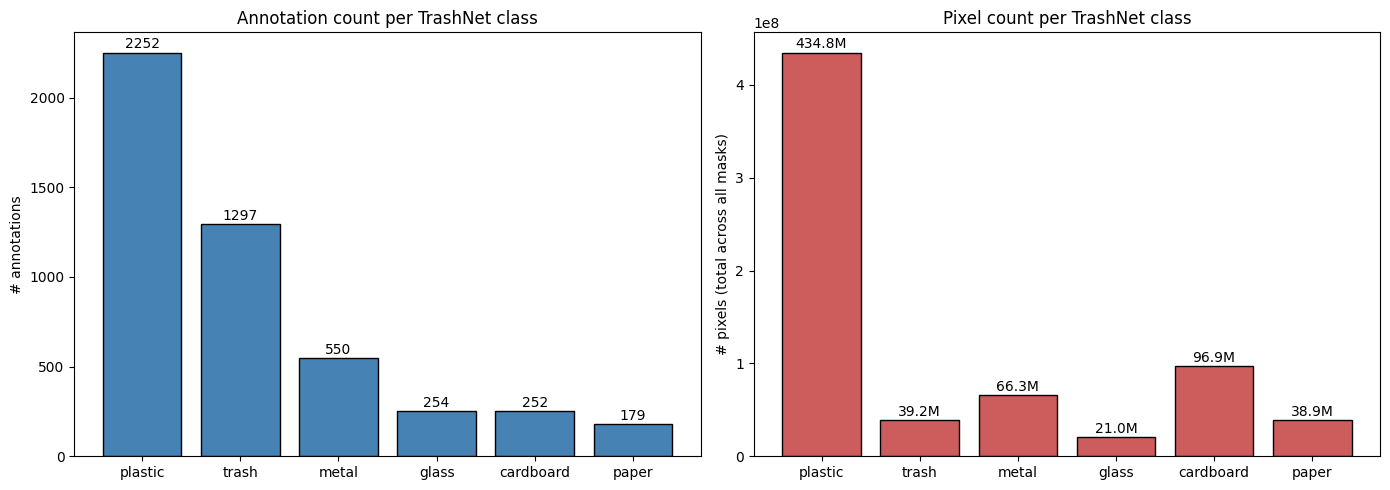

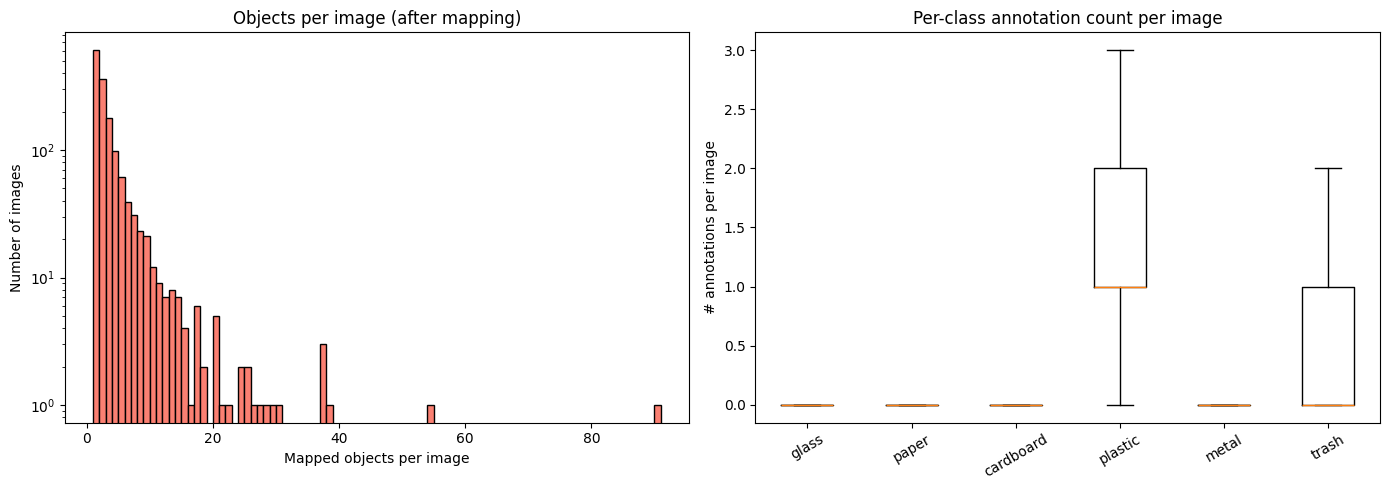

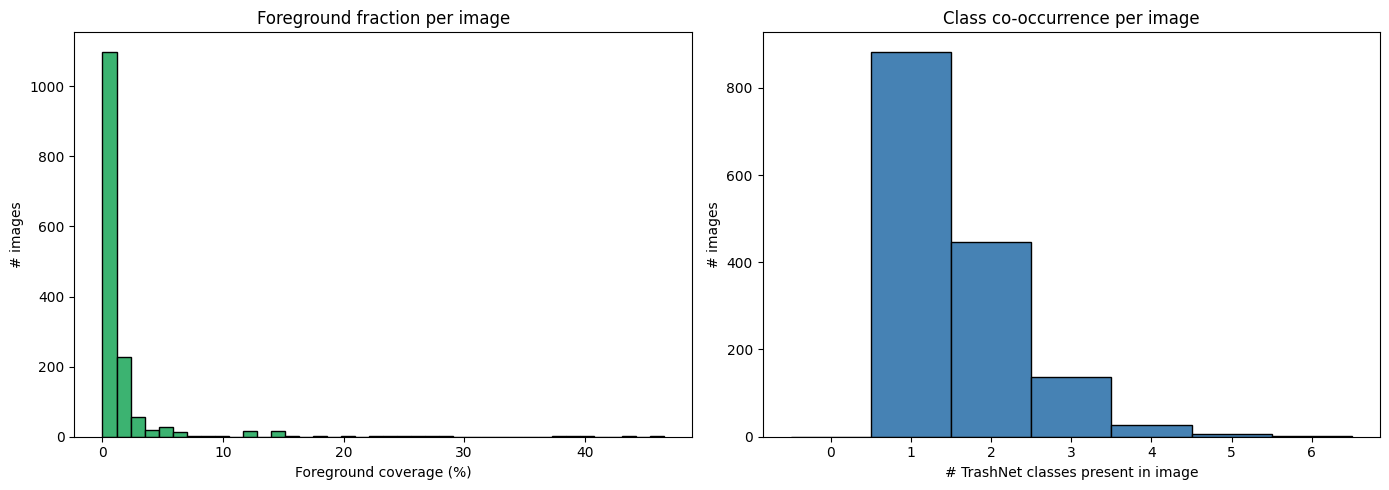


Foreground coverage: mean=1.7%, median=0.7%, min=0.02%, max=46.6%
Classes per image : mean=1.55, max=6, images with 1 class=883


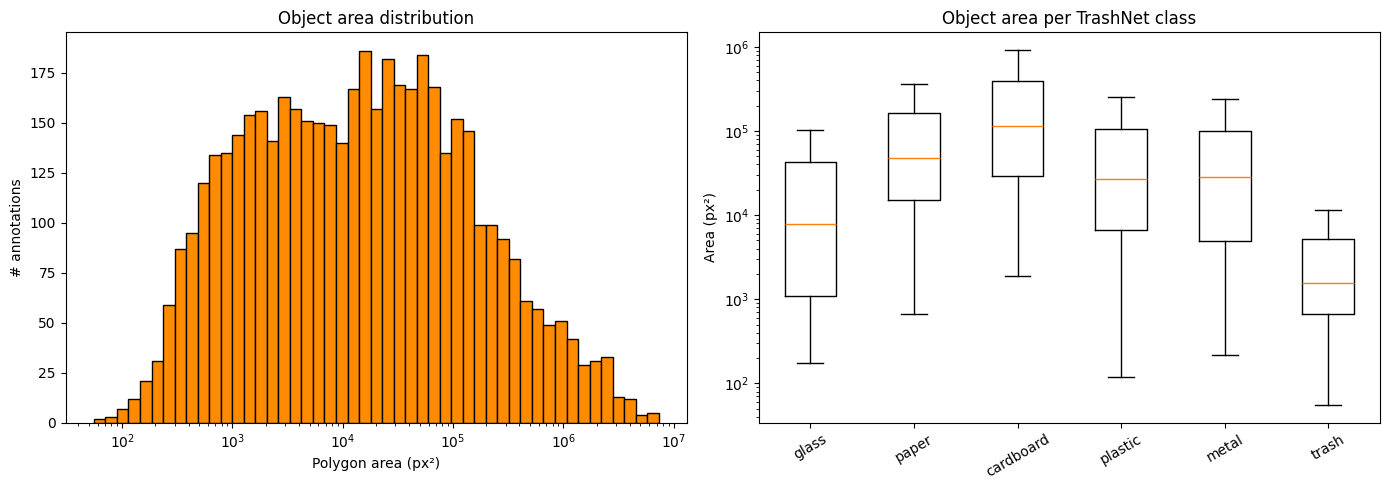


Area stats:
  min    : 56
  median : 14245
  mean   : 150407
  max    : 7328036
  < 500 px² : 327 (6.8%)

[6.5] EXIF alignment diagnostic
  cv2-loaded images with transposed shape: 0/200 (0.0%)


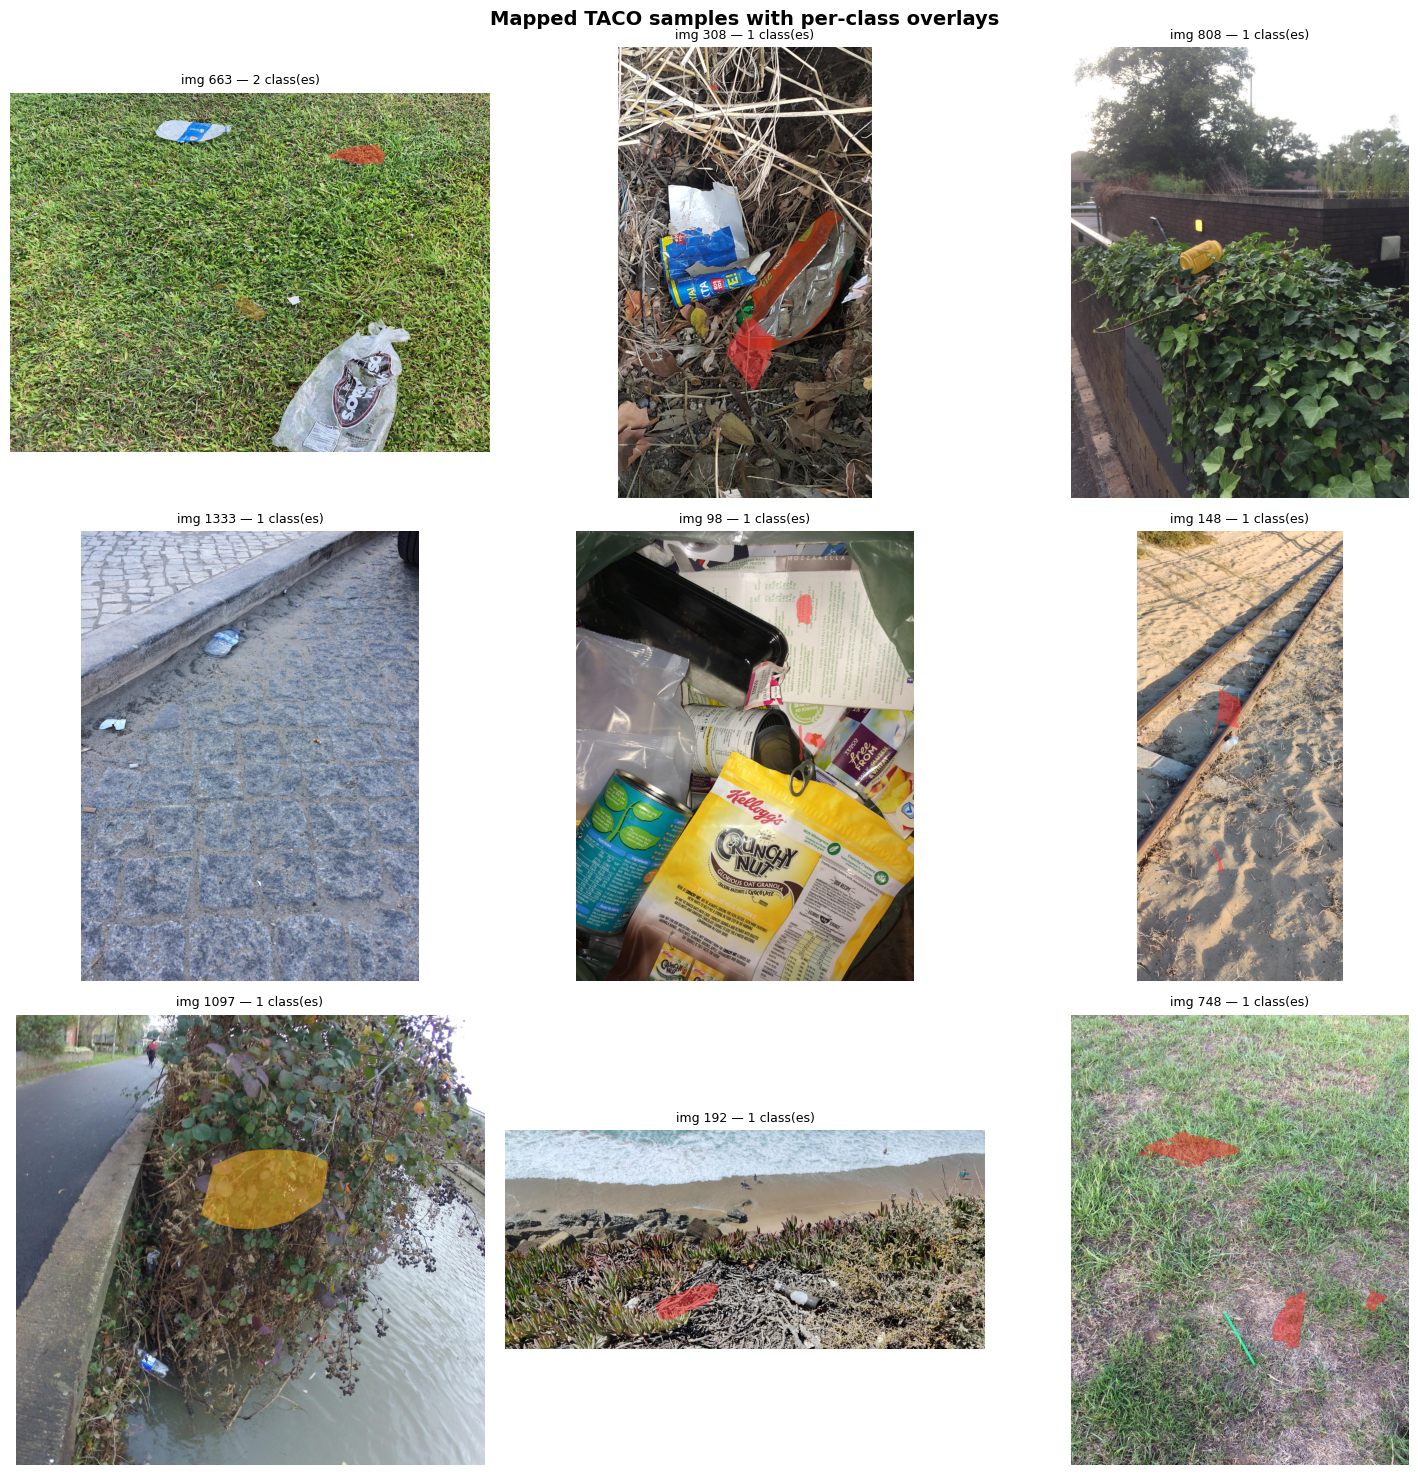

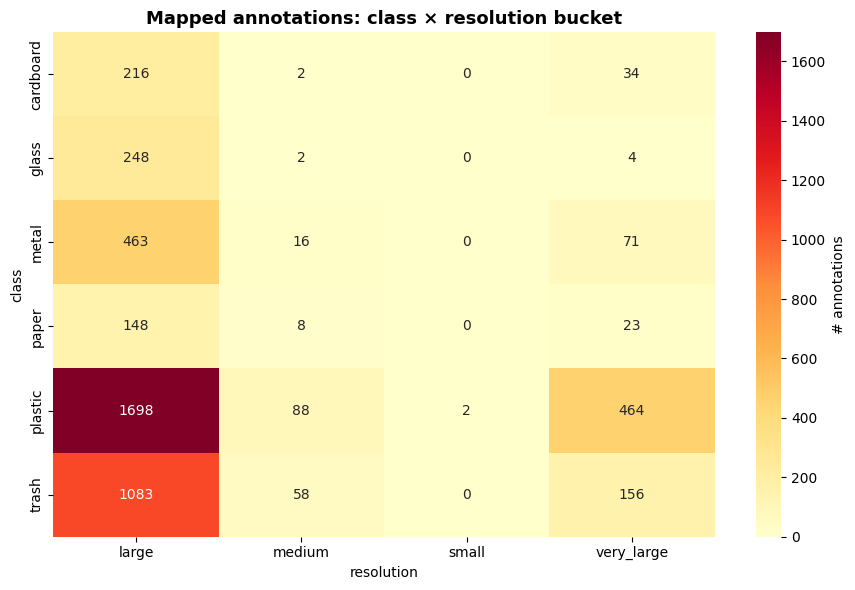

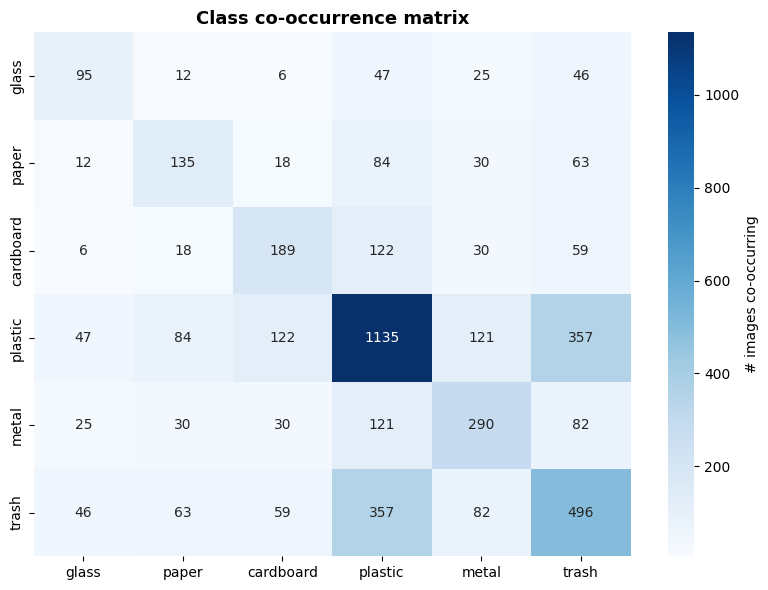


EDA SUMMARY (mapped)
Images with ≥1 mapped class : 1500
Total mapped annotations    : 4784
Coverage                    : 100.0%
Class imbalance (top/bottom): plastic (2252) vs paper (179) → 12.6:1
Mean classes/image          : 1.55
Mean foreground coverage    : 1.7%
Tiny objects (<500 px²)     : 327 (6.8%)

All EDA figures saved to: /kaggle/working/taco_trashnet/eda/


In [1]:
# ============================================================================
# TACO → TrashNet Mapping + Rasterization + EDA (v5 — EXIF fix)
# Input : /kaggle/input/datasets/kneroma/tacotrashdataset
# Output: /kaggle/working/taco_trashnet/
# ============================================================================

import os
import json
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import cv2
from tqdm.auto import tqdm
from PIL import Image, ImageOps

# ============================================================
# 0. Config
# ============================================================
TACO_ROOT  = "/kaggle/input/datasets/kneroma/tacotrashdataset"
OUT_DIR    = "/kaggle/working/taco_trashnet"
MASK_DIR   = os.path.join(OUT_DIR, "masks")
PERCLS_DIR = os.path.join(OUT_DIR, "masks_perclass")
EDA_DIR    = os.path.join(OUT_DIR, "eda")
os.makedirs(MASK_DIR, exist_ok=True)
os.makedirs(PERCLS_DIR, exist_ok=True)
os.makedirs(EDA_DIR, exist_ok=True)

TRASHNET_CLASSES = ["glass", "paper", "cardboard", "plastic", "metal", "trash"]
TRASHNET_NAME_TO_ID = {n: i for i, n in enumerate(TRASHNET_CLASSES)}

MIN_AREA_PX = 20
SAVE_PERCLASS = True

# ============================================================
# 1. Locate annotations + images
# ============================================================
def find_annotations(root):
    for r, _, files in os.walk(root):
        if "annotations.json" in files:
            return os.path.join(r, "annotations.json")
    return None

def find_image_dir(root, ann_file):
    candidates = [
        os.path.dirname(ann_file),
        os.path.dirname(os.path.dirname(ann_file)),
        os.path.join(os.path.dirname(ann_file), "data"),
        os.path.join(os.path.dirname(os.path.dirname(ann_file)), "data"),
        root,
    ]
    for cand in candidates:
        if not os.path.isdir(cand):
            continue
        for r, _, files in os.walk(cand):
            if any(f.lower().endswith((".jpg", ".jpeg", ".png"))
                   for f in files):
                return cand
    return None

def resolve_image_path(img_info, img_dir, taco_root):
    fname = img_info["file_name"]
    base = os.path.basename(fname)
    candidates = [
        os.path.join(img_dir, fname),
        os.path.join(img_dir, "data", fname),
        os.path.join(img_dir, base),
    ]
    if os.path.isdir(img_dir):
        for sub in os.listdir(img_dir):
            sub_path = os.path.join(img_dir, sub)
            if os.path.isdir(sub_path):
                candidates.append(os.path.join(sub_path, base))
    for p in candidates:
        if os.path.exists(p):
            return p
    for r, _, files in os.walk(taco_root):
        if base in files:
            return os.path.join(r, base)
    return None

def load_image_at_declared_size(img_info, img_dir, taco_root):
    """Load image with EXIF rotation applied, then force to declared dims.
    cv2.imread ignores EXIF; PIL + ImageOps.exif_transpose applies it.
    This guarantees pixel-alignment with the rasterized masks even for
    phone photos with rotation tags."""
    path = resolve_image_path(img_info, img_dir, taco_root)
    if path is None:
        return None

    # --- try PIL first (applies EXIF) ---
    try:
        pil_img = Image.open(path)
        pil_img = ImageOps.exif_transpose(pil_img)
        img = np.array(pil_img.convert("RGB"))
    except Exception:
        # --- fallback to cv2 ---
        img = cv2.imread(path)
        if img is None:
            return None
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # --- force to declared dims ---
    H, W = img_info["height"], img_info["width"]
    if img.shape[:2] == (H, W):
        return img

    # if transposed, rotate first (resizing a rotated image keeps it rotated)
    if img.shape[:2] == (W, H):
        img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)

    # final safety-net resize
    if img.shape[:2] != (H, W):
        img = cv2.resize(img, (W, H), interpolation=cv2.INTER_AREA)
    return img

ANN_FILE = find_annotations(TACO_ROOT)
IMG_DIR  = find_image_dir(TACO_ROOT, ANN_FILE)
print(f"ANN_FILE : {ANN_FILE}")
print(f"IMG_DIR  : {IMG_DIR}")

with open(ANN_FILE) as f:
    coco = json.load(f)

images      = coco["images"]
annotations = coco["annotations"]
categories  = coco["categories"]
cat_id_to_name = {c["id"]: c["name"] for c in categories}

# ============================================================
# 2. TACO → TrashNet mapping
# ============================================================
TRASHNET_MAP = {
    # --- GLASS ---
    "Glass jar": "glass", "Broken glass": "glass",
    "Glass cup": "glass", "Glass bottle": "glass",

    # --- PAPER ---
    "Paper": "paper", "Normal paper": "paper",
    "Magazine paper": "paper", "Tissues": "paper",
    "Paper bag": "paper", "Wrapping paper": "paper",
    "Paper straw": "paper",

    # --- CARDBOARD ---
    "Carton": "cardboard", "Other carton": "cardboard",
    "Drink carton": "cardboard", "Meal carton": "cardboard",
    "Egg carton": "cardboard", "Corrugated carton": "cardboard",
    "Pizza box": "cardboard", "Toilet tube": "cardboard",
    "Carded blister pack": "cardboard",

    # --- PLASTIC ---
    "Clear plastic bottle": "plastic", "Other plastic bottle": "plastic",
    "Plastic bottle cap": "plastic", "Plastic film": "plastic",
    "Other plastic wrapper": "plastic", "Single-use carrier bag": "plastic",
    "Polypropylene bag": "plastic", "Crisp packet": "plastic",
    "Garbage bag": "plastic", "Plastic straw": "plastic",
    "Plastic utensils": "plastic", "Disposable plastic cup": "plastic",
    "Other plastic cup": "plastic", "Foam cup": "plastic",
    "Foam food container": "plastic",
    "Disposable food container": "plastic",
    "Other plastic container": "plastic", "Spread tub": "plastic",
    "Tupperware": "plastic", "Plastic lid": "plastic",
    "Other plastic": "plastic", "Styrofoam piece": "plastic",
    "Six pack rings": "plastic", "Squeezable tube": "plastic",
    "Plastic glooves": "plastic", "Plastified paper bag": "plastic",

    # --- METAL ---
    "Drink can": "metal", "Food Can": "metal", "Aerosol": "metal",
    "Metal bottle cap": "metal", "Metal lid": "metal",
    "Pop tab": "metal", "Aluminium foil": "metal",
    "Aluminium blister pack": "metal", "Scrap metal": "metal",

    # --- TRASH ---
    "Cigarette": "trash", "Unlabeled litter": "trash",
    "Food waste": "trash", "Shoe": "trash",
    "Battery": "trash", "Rope & strings": "trash",
    "Paper cup": "trash",
}

cat_id_to_trashnet = {}
unmapped = []
for c in categories:
    name = c["name"]
    if name in TRASHNET_MAP:
        cat_id_to_trashnet[c["id"]] = TRASHNET_NAME_TO_ID[TRASHNET_MAP[name]]
    else:
        unmapped.append((c["id"], name))

print(f"\nMapped   : {len(cat_id_to_trashnet)} / {len(categories)} categories")
print(f"Unmapped : {len(unmapped)}")
if unmapped:
    for cid, name in unmapped:
        print(f"  id={cid}  {name}")

# ============================================================
# 3. Process every image
# ============================================================
anns_by_img = defaultdict(list)
for ann in annotations:
    if ann["category_id"] in cat_id_to_trashnet:
        anns_by_img[ann["image_id"]].append(ann)

kept_anns = []
kept_imgs = []
class_counts_anns = Counter()
class_counts_px   = Counter()
missing_imgs = []

img_class_anns = {}
img_class_px   = {}

print(f"\nProcessing {len(images)} images...")
for img_info in tqdm(images, desc="rasterizing"):
    img_id = img_info["id"]
    anns = anns_by_img.get(img_id, [])
    if not anns:
        continue

    img_path = resolve_image_path(img_info, IMG_DIR, TACO_ROOT)
    if img_path is None:
        missing_imgs.append(img_info["file_name"])
        continue

    H, W = img_info["height"], img_info["width"]
    percls = np.zeros((H, W), dtype=np.uint8)
    binary = np.zeros((H, W), dtype=np.uint8)

    per_img_anns = Counter()
    for ann in anns:
        class_id = cat_id_to_trashnet[ann["category_id"]]
        seg = ann.get("segmentation", [])
        if not isinstance(seg, list) or len(seg) == 0:
            continue

        polys = []
        for poly in seg:
            pts = np.array(poly).reshape(-1, 2).astype(np.int32)
            if len(pts) < 3:
                continue
            poly_area = 0.5 * abs(np.dot(pts[:, 0], np.roll(pts[:, 1], -1)) -
                                  np.dot(pts[:, 1], np.roll(pts[:, 0], -1)))
            if poly_area < MIN_AREA_PX:
                continue
            polys.append(pts)

        if len(polys) == 0:
            continue

        cv2.fillPoly(binary, polys, 1)
        paint = (percls == 0).astype(np.uint8)
        tmp = np.zeros((H, W), dtype=np.uint8)
        cv2.fillPoly(tmp, polys, 1)
        newly_painted = (tmp == 1) & (paint == 1)
        percls[newly_painted] = class_id + 1

        class_counts_anns[class_id] += 1
        per_img_anns[class_id] += 1

    mask_fname = os.path.splitext(os.path.basename(img_info["file_name"]))[0] + ".png"
    cv2.imwrite(os.path.join(MASK_DIR, mask_fname), binary * 255)

    per_img_px = {}
    if SAVE_PERCLASS:
        cv2.imwrite(os.path.join(PERCLS_DIR, mask_fname), percls)
        for cid in range(len(TRASHNET_CLASSES)):
            px = int((percls == cid + 1).sum())
            class_counts_px[cid] += px
            per_img_px[cid] = px

    img_class_anns[img_id] = dict(per_img_anns)
    img_class_px[img_id] = per_img_px

    for ann in anns:
        class_id = cat_id_to_trashnet[ann["category_id"]]
        kept_anns.append({
            "id": len(kept_anns),
            "image_id": img_id,
            "category_id": class_id,
            "segmentation": ann.get("segmentation", []),
            "area": ann.get("area", 0),
            "bbox": ann.get("bbox", []),
            "iscrowd": ann.get("iscrowd", 0),
        })

    kept_imgs.append({
        "id": img_id,
        "file_name": img_info["file_name"],
        "width": W,
        "height": H,
        "mask_file": mask_fname,
    })

# ============================================================
# 4. Save filtered COCO JSON
# ============================================================
filtered_coco = {
    "info": {
        "description": "TACO filtered to TrashNet's 6 classes",
        "source": TACO_ROOT,
        "min_area_px": MIN_AREA_PX,
    },
    "licenses": [],
    "images": kept_imgs,
    "annotations": kept_anns,
    "categories": [
        {"id": i, "name": n, "supercategory": "waste"}
        for i, n in enumerate(TRASHNET_CLASSES)
    ],
}
OUT_JSON = os.path.join(OUT_DIR, "taco_trashnet_mapped.json")
with open(OUT_JSON, "w") as f:
    json.dump(filtered_coco, f, indent=2)

print(f"\nSaved JSON  -> {OUT_JSON}")
print(f"Saved masks -> {MASK_DIR}/")

# ============================================================
# 5. Mapping report
# ============================================================
report_lines = []
report_lines.append("=" * 70)
report_lines.append("TACO → TRASHNET MAPPING REPORT")
report_lines.append("=" * 70)
report_lines.append(f"Input root          : {TACO_ROOT}")
report_lines.append(f"Original images     : {len(images)}")
report_lines.append(f"Original annotations: {len(annotations)}")
report_lines.append(f"Original categories : {len(categories)}")
report_lines.append("")
report_lines.append(f"Kept images         : {len(kept_imgs)}")
report_lines.append(f"Kept annotations    : {len(kept_anns)}")
report_lines.append(f"Coverage            : "
                    f"{100*len(kept_anns)/len(annotations):.1f}% of anns")
report_lines.append(f"Missing image files : {len(missing_imgs)}")
report_lines.append("")
report_lines.append("Per-TrashNet-class annotation counts:")
report_lines.append(f"  {'class':<12}{'anns':>8}{'pixels':>14}")
for cid, name in enumerate(TRASHNET_CLASSES):
    report_lines.append(
        f"  {name:<12}{class_counts_anns.get(cid, 0):>8}"
        f"{class_counts_px.get(cid, 0):>14,}"
    )
report_lines.append("")
report_lines.append(f"Unmapped categories ({len(unmapped)}):")
for cid, name in unmapped:
    report_lines.append(f"  id={cid}  {name}")
report = "\n".join(report_lines)
print("\n" + report)

with open(os.path.join(OUT_DIR, "mapping_report.txt"), "w") as f:
    f.write(report)

# ============================================================================
# 6. EDA ON THE MAPPED DATASET
# ============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import random

print("\n" + "=" * 70)
print("EDA: MAPPED DATASET")
print("=" * 70)

# ------------------------------------------------------------
# 6.1 Class imbalance
# ------------------------------------------------------------
eda_class_df = pd.DataFrame([
    {"class": name,
     "anns": class_counts_anns.get(cid, 0),
     "pixels": class_counts_px.get(cid, 0)}
    for cid, name in enumerate(TRASHNET_CLASSES)
])
total_anns   = eda_class_df["anns"].sum()
total_pixels = eda_class_df["pixels"].sum()
eda_class_df["anns_pct"]   = 100 * eda_class_df["anns"]   / max(1, total_anns)
eda_class_df["pixels_pct"] = 100 * eda_class_df["pixels"] / max(1, total_pixels)
eda_class_df = eda_class_df.sort_values("anns", ascending=False).reset_index(drop=True)

print("\nClass distribution (mapped):")
print(eda_class_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(eda_class_df["class"], eda_class_df["anns"],
            color="steelblue", edgecolor="black")
axes[0].set_ylabel("# annotations")
axes[0].set_title("Annotation count per TrashNet class")
for i, v in enumerate(eda_class_df["anns"]):
    axes[0].text(i, v + max(eda_class_df["anns"]) * 0.01,
                 str(v), ha="center", fontsize=10)

axes[1].bar(eda_class_df["class"], eda_class_df["pixels"],
            color="indianred", edgecolor="black")
axes[1].set_ylabel("# pixels (total across all masks)")
axes[1].set_title("Pixel count per TrashNet class")
for i, v in enumerate(eda_class_df["pixels"]):
    axes[1].text(i, v + max(eda_class_df["pixels"]) * 0.01,
                 f"{v/1e6:.1f}M", ha="center", fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "eda_class_distribution.png"),
            dpi=120, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6.2 Objects per image
# ------------------------------------------------------------
objs_per_img_mapped = Counter()
for ann in kept_anns:
    objs_per_img_mapped[ann["image_id"]] += 1

counts = list(objs_per_img_mapped.values())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(counts, bins=range(1, max(counts) + 2),
             color="salmon", edgecolor="black")
axes[0].set_xlabel("Mapped objects per image")
axes[0].set_ylabel("Number of images")
axes[0].set_title("Objects per image (after mapping)")
axes[0].set_yscale("log")

class_per_img_counts = defaultdict(list)
for img_id, cls_map in img_class_anns.items():
    for cid in range(len(TRASHNET_CLASSES)):
        class_per_img_counts[cid].append(cls_map.get(cid, 0))

box_data = [class_per_img_counts[cid] for cid in range(6)]
axes[1].boxplot(box_data, tick_labels=TRASHNET_CLASSES, showfliers=False)
axes[1].set_ylabel("# annotations per image")
axes[1].set_title("Per-class annotation count per image")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "eda_objects_per_image.png"),
            dpi=120, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6.3 Binary mask coverage
# ------------------------------------------------------------
mask_coverages = []
for img in kept_imgs:
    m = cv2.imread(os.path.join(MASK_DIR, img["mask_file"]),
                   cv2.IMREAD_GRAYSCALE)
    if m is None:
        continue
    mask_coverages.append((m > 127).mean())

mask_coverages = np.array(mask_coverages)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(mask_coverages * 100, bins=40, color="mediumseagreen",
             edgecolor="black")
axes[0].set_xlabel("Foreground coverage (%)")
axes[0].set_ylabel("# images")
axes[0].set_title("Foreground fraction per image")

n_classes_per_img = [sum(1 for c in range(6)
                         if img_class_px.get(img["id"], {}).get(c, 0) > 0)
                     for img in kept_imgs]
n_classes_per_img = np.array(n_classes_per_img)
axes[1].hist(n_classes_per_img, bins=range(0, 8), color="steelblue",
             edgecolor="black", align="left")
axes[1].set_xlabel("# TrashNet classes present in image")
axes[1].set_ylabel("# images")
axes[1].set_title("Class co-occurrence per image")

plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "eda_mask_coverage.png"),
            dpi=120, bbox_inches="tight")
plt.show()

print(f"\nForeground coverage: mean={mask_coverages.mean()*100:.1f}%, "
      f"median={np.median(mask_coverages)*100:.1f}%, "
      f"min={mask_coverages.min()*100:.2f}%, "
      f"max={mask_coverages.max()*100:.1f}%")
print(f"Classes per image : mean={n_classes_per_img.mean():.2f}, "
      f"max={n_classes_per_img.max()}, "
      f"images with 1 class={int((n_classes_per_img == 1).sum())}")

# ------------------------------------------------------------
# 6.4 Object size distribution
# ------------------------------------------------------------
kept_areas = [a["area"] for a in kept_anns if a.get("area", 0) > 0]
kept_areas = np.array(kept_areas)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(kept_areas,
             bins=np.logspace(np.log10(max(1, kept_areas.min())),
                              np.log10(kept_areas.max() + 1), 50),
             color="darkorange", edgecolor="black")
axes[0].set_xscale("log")
axes[0].set_xlabel("Polygon area (px²)")
axes[0].set_ylabel("# annotations")
axes[0].set_title("Object area distribution")

areas_per_class = defaultdict(list)
for ann in kept_anns:
    if ann.get("area", 0) > 0:
        areas_per_class[ann["category_id"]].append(ann["area"])
box_data = [areas_per_class.get(cid, [np.nan]) for cid in range(6)]
axes[1].boxplot(box_data, tick_labels=TRASHNET_CLASSES, showfliers=False)
axes[1].set_yscale("log")
axes[1].set_ylabel("Area (px²)")
axes[1].set_title("Object area per TrashNet class")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "eda_object_size.png"),
            dpi=120, bbox_inches="tight")
plt.show()

print(f"\nArea stats:")
print(f"  min    : {kept_areas.min():.0f}")
print(f"  median : {np.median(kept_areas):.0f}")
print(f"  mean   : {kept_areas.mean():.0f}")
print(f"  max    : {kept_areas.max():.0f}")
small = (kept_areas < 500).sum()
print(f"  < 500 px² : {small} ({100*small/len(kept_areas):.1f}%)")

# ------------------------------------------------------------
# 6.5 Sample grid (9 random images) with per-class overlays
#      FIXED: EXIF-aware loading + rotate-on-transpose
# ------------------------------------------------------------
random.seed(7)
sample_imgs = random.sample(kept_imgs, min(9, len(kept_imgs)))

# --- diagnostic: how many TACO images have EXIF rotation issues? ---
print("\n[6.5] EXIF alignment diagnostic")
rotated = 0
total = 0
for img in kept_imgs[:200]:
    p = resolve_image_path(img, IMG_DIR, TACO_ROOT)
    if p is None: continue
    raw = cv2.imread(p)
    if raw is None: continue
    total += 1
    if (img["width"], img["height"]) == (raw.shape[0], raw.shape[1]):
        rotated += 1
print(f"  cv2-loaded images with transposed shape: {rotated}/{total} "
      f"({100*rotated/max(1,total):.1f}%)")

colors = {
    "glass":     (0.2, 0.4, 1.0),
    "paper":     (0.2, 0.9, 0.2),
    "cardboard": (0.7, 0.5, 0.2),
    "plastic":   (1.0, 0.2, 0.2),
    "metal":     (1.0, 0.7, 0.1),
    "trash":     (0.5, 0.5, 0.5),
}

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

for ax, img in zip(axes, sample_imgs):
    rgb = load_image_at_declared_size(img, IMG_DIR, TACO_ROOT)
    percls = cv2.imread(os.path.join(PERCLS_DIR, img["mask_file"]),
                        cv2.IMREAD_GRAYSCALE)
    if rgb is None or percls is None:
        ax.text(0.5, 0.5, "missing", ha="center",
                transform=ax.transAxes)
        ax.axis("off")
        continue

    # --- align mask to image: rotate first if transposed, then resize ---
    if percls.shape[:2] != rgb.shape[:2]:
        H, W = img["height"], img["width"]
        if percls.shape[0] == W and percls.shape[1] == H:
            percls = cv2.rotate(percls, cv2.ROTATE_90_CLOCKWISE)
        if percls.shape[:2] != rgb.shape[:2]:
            percls = cv2.resize(percls, (rgb.shape[1], rgb.shape[0]),
                                interpolation=cv2.INTER_NEAREST)

    overlay = rgb.copy()
    legend = []
    for cid, name in enumerate(TRASHNET_CLASSES):
        sel = (percls == cid + 1)
        if sel.any():
            c = np.array(colors[name]) * 255
            overlay[sel] = (0.5 * overlay[sel] + 0.5 * c).astype(np.uint8)
            legend.append(f"{name}({int(sel.sum())}px)")
    ax.imshow(overlay)
    ax.set_title(f"img {img['id']} — {len(legend)} class(es)", fontsize=9)
    ax.axis("off")

plt.suptitle("Mapped TACO samples with per-class overlays",
             fontsize=14, weight="bold")
plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "eda_sample_grid.png"),
            dpi=120, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6.6 Class × resolution heatmap
# ------------------------------------------------------------
def res_bucket(w, h):
    m = max(w, h)
    if m <= 1024:  return "small"
    if m <= 2048:  return "medium"
    if m <= 4096:  return "large"
    return "very_large"

img_id_to_res = {img["id"]: res_bucket(img["width"], img["height"])
                 for img in kept_imgs}
rows = []
for ann in kept_anns:
    rows.append({
        "class": TRASHNET_CLASSES[ann["category_id"]],
        "resolution": img_id_to_res[ann["image_id"]],
    })
cross_df = pd.crosstab(pd.DataFrame(rows)["class"],
                        pd.DataFrame(rows)["resolution"])

plt.figure(figsize=(9, 6))
sns.heatmap(cross_df, annot=True, fmt="d", cmap="YlOrRd",
            cbar_kws={"label": "# annotations"})
plt.title("Mapped annotations: class × resolution bucket",
          fontsize=13, weight="bold")
plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "eda_class_resolution.png"),
            dpi=120, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 6.7 Class co-occurrence matrix
# ------------------------------------------------------------
co_occur = np.zeros((6, 6), dtype=int)
for img_id in img_class_anns:
    present = [cid for cid in range(6) if img_class_anns[img_id].get(cid, 0) > 0]
    for a in present:
        for b in present:
            co_occur[a, b] += 1

plt.figure(figsize=(8, 6))
sns.heatmap(co_occur, annot=True, fmt="d", cmap="Blues",
            xticklabels=TRASHNET_CLASSES,
            yticklabels=TRASHNET_CLASSES,
            cbar_kws={"label": "# images co-occurring"})
plt.title("Class co-occurrence matrix", fontsize=13, weight="bold")
plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "eda_class_cooccurrence.png"),
            dpi=120, bbox_inches="tight")
plt.show()

# ============================================================
# 7. EDA SUMMARY
# ============================================================
print("\n" + "=" * 70)
print("EDA SUMMARY (mapped)")
print("=" * 70)
print(f"Images with ≥1 mapped class : {len(kept_imgs)}")
print(f"Total mapped annotations    : {len(kept_anns)}")
print(f"Coverage                    : "
      f"{100*len(kept_anns)/len(annotations):.1f}%")
print(f"Class imbalance (top/bottom): "
      f"{eda_class_df.iloc[0]['class']} ({eda_class_df.iloc[0]['anns']}) vs "
      f"{eda_class_df.iloc[-1]['class']} ({eda_class_df.iloc[-1]['anns']}) "
      f"→ {eda_class_df.iloc[0]['anns']/max(1, eda_class_df.iloc[-1]['anns']):.1f}:1")
print(f"Mean classes/image          : {n_classes_per_img.mean():.2f}")
print(f"Mean foreground coverage    : {mask_coverages.mean()*100:.1f}%")
print(f"Tiny objects (<500 px²)     : {small} "
      f"({100*small/len(kept_areas):.1f}%)")
print(f"\nAll EDA figures saved to: {EDA_DIR}/")

Device: cuda

Loading models...
  ✓ v3, v4 loaded

TrashNet val pairs: 374
TACO: 1500 images, 4784 annotations

EVALUATING v3 AND v4

Evaluating v3 on TrashNet val...
Evaluating v4 on TrashNet val...
Evaluating v3 on TACO...
Evaluating v4 on TACO...

NUMERIC SUMMARY

Dataset           Metric                      v3        v4         Δ
--------------------------------------------------------------------
TrashNet val      Mean IoU                0.9234    0.8106   -0.1128
                  Median IoU              0.9825    0.9681   -0.0144
                  Precision               0.9895    0.9898   +0.0004
                  Recall                  0.8722    0.6815   -0.1907
TACO              Mean IoU                0.0477    0.0676   +0.0200
                  Median IoU              0.0072    0.0048   -0.0025
                  Precision               0.0221    0.0524   +0.0304
                  Recall                  0.7776    0.4801   -0.2975
                  FP in bg                

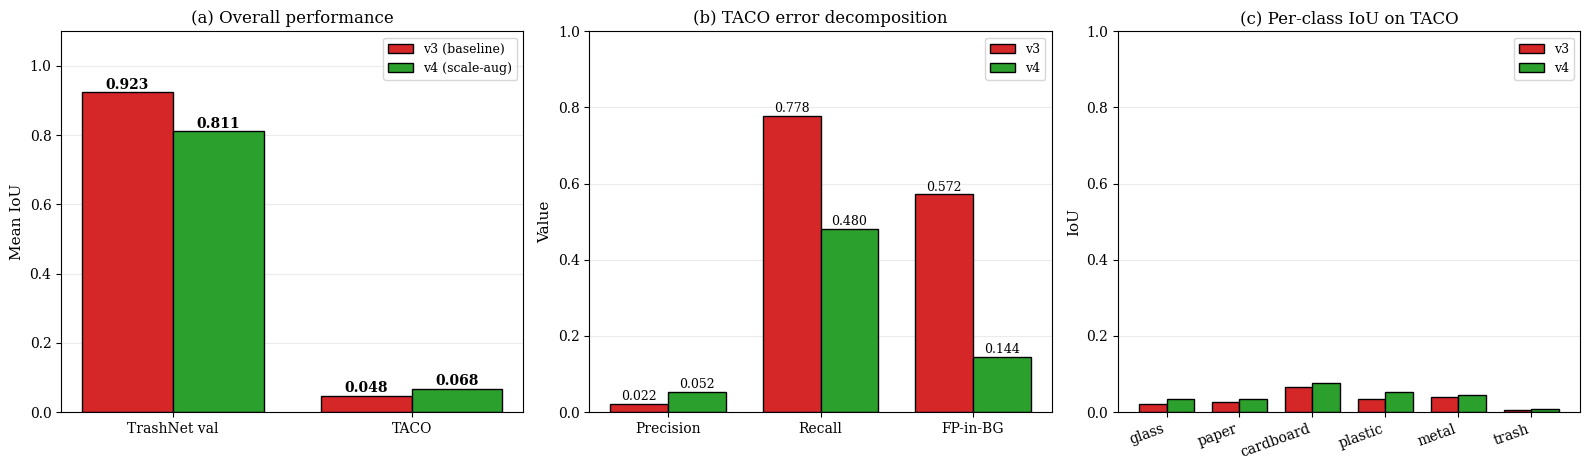

  ✓ fig1_main_comparison


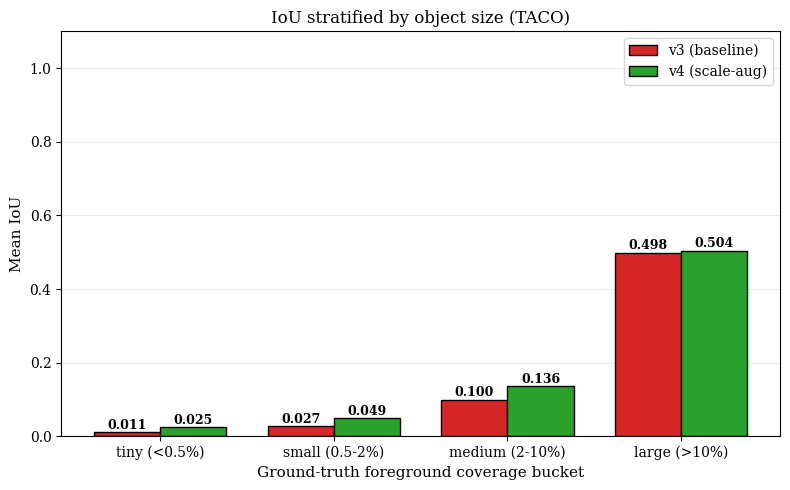

  ✓ fig2_size_buckets


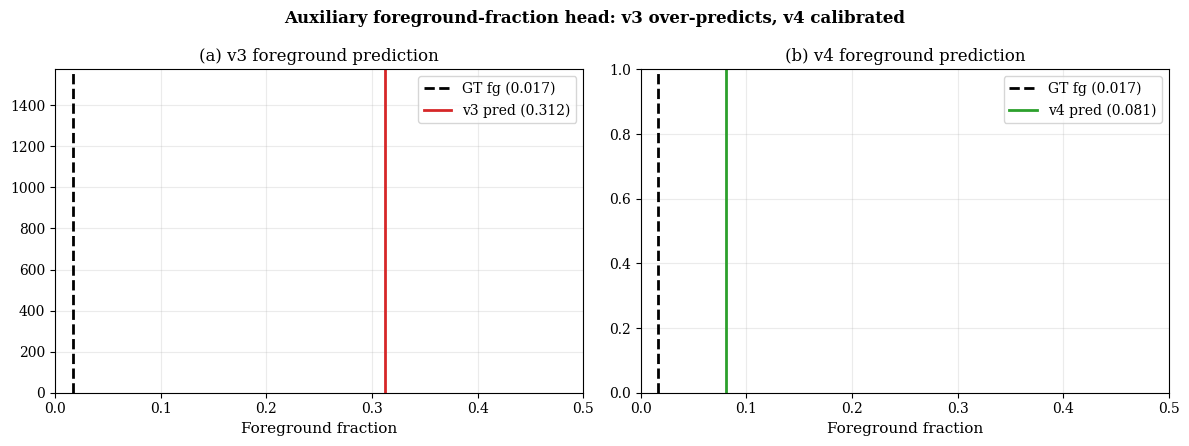

  ✓ fig3_fg_fraction


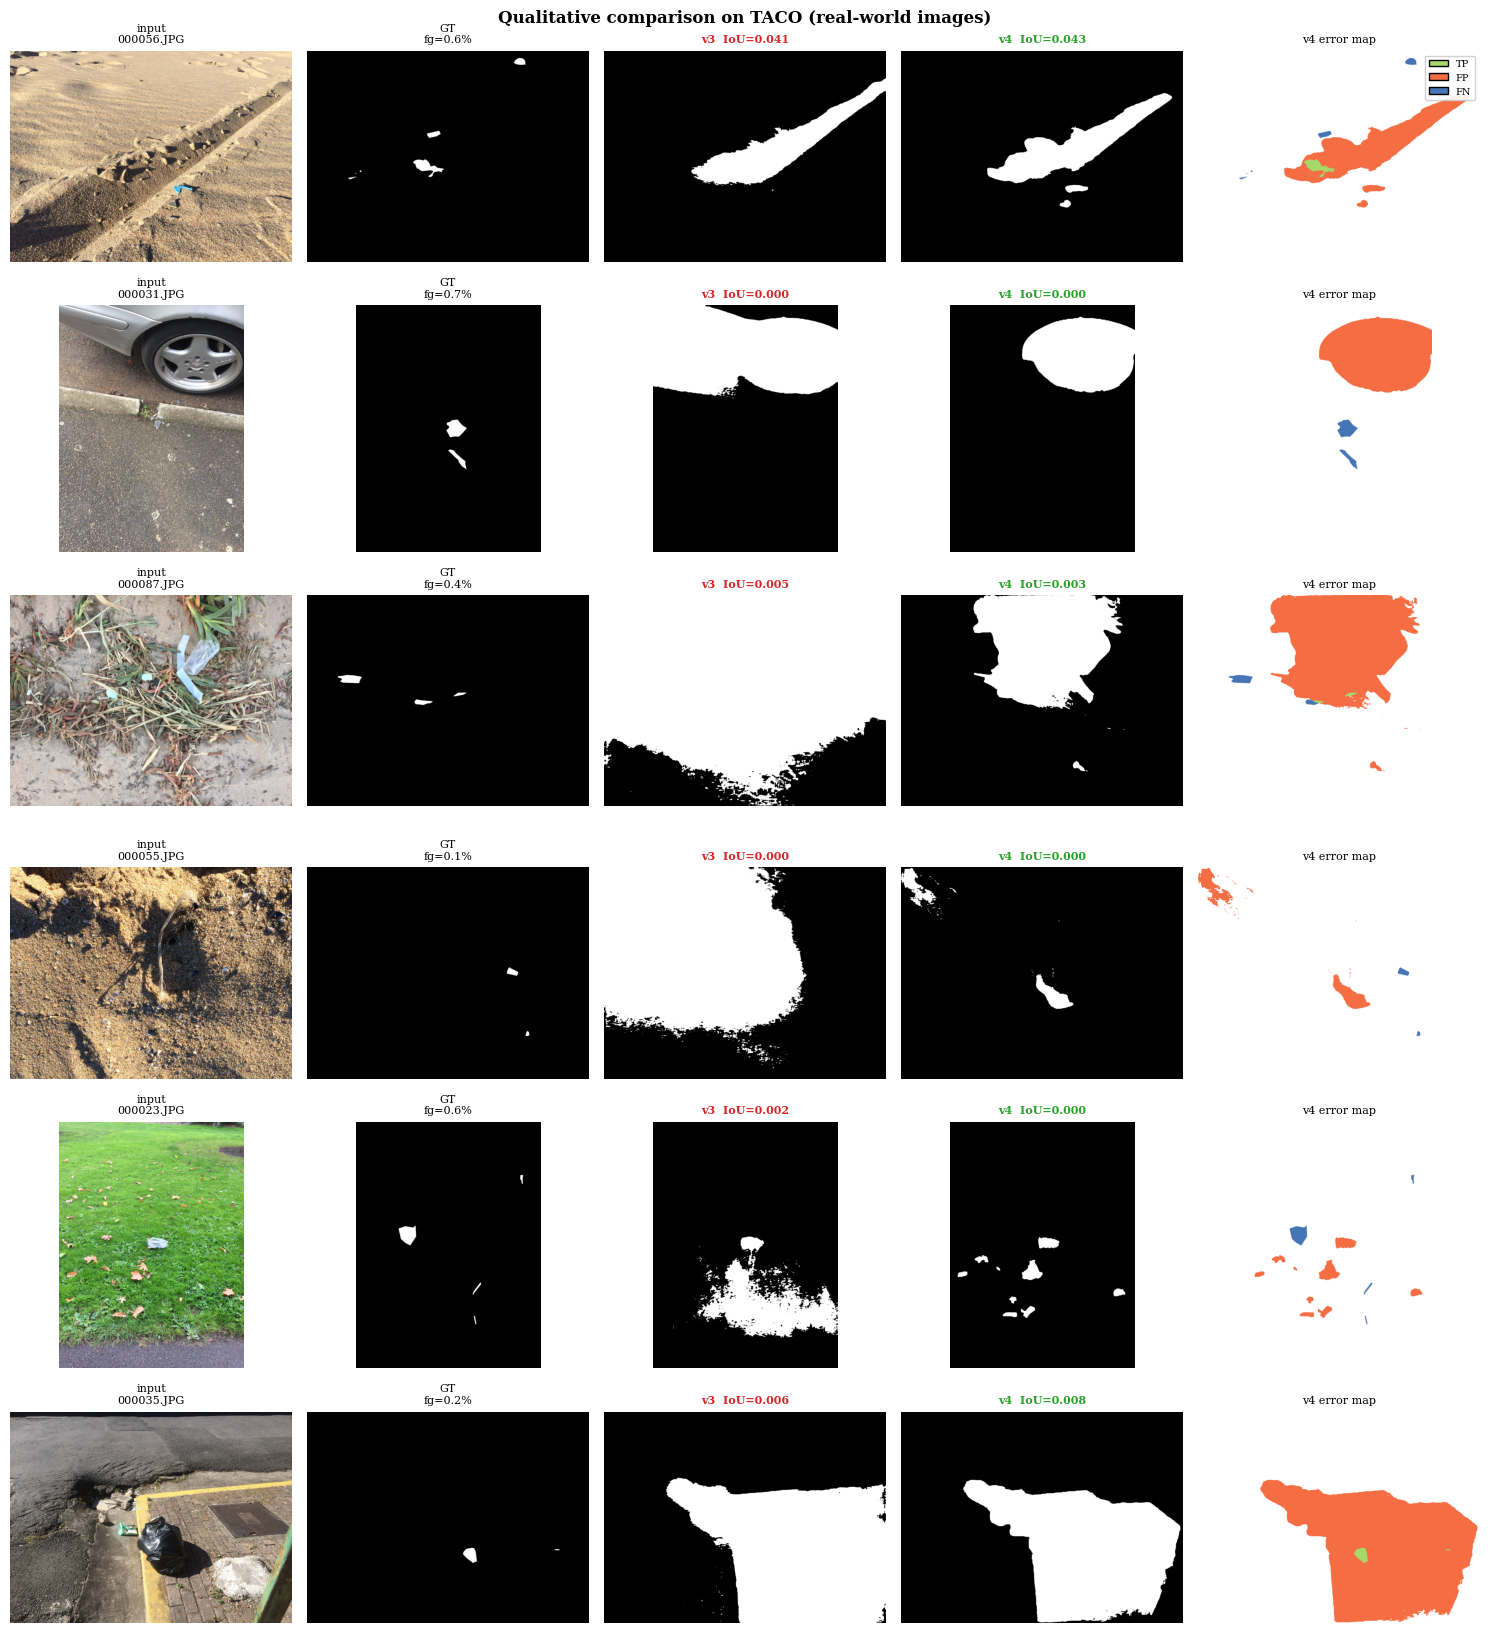

  ✓ fig4_qualitative


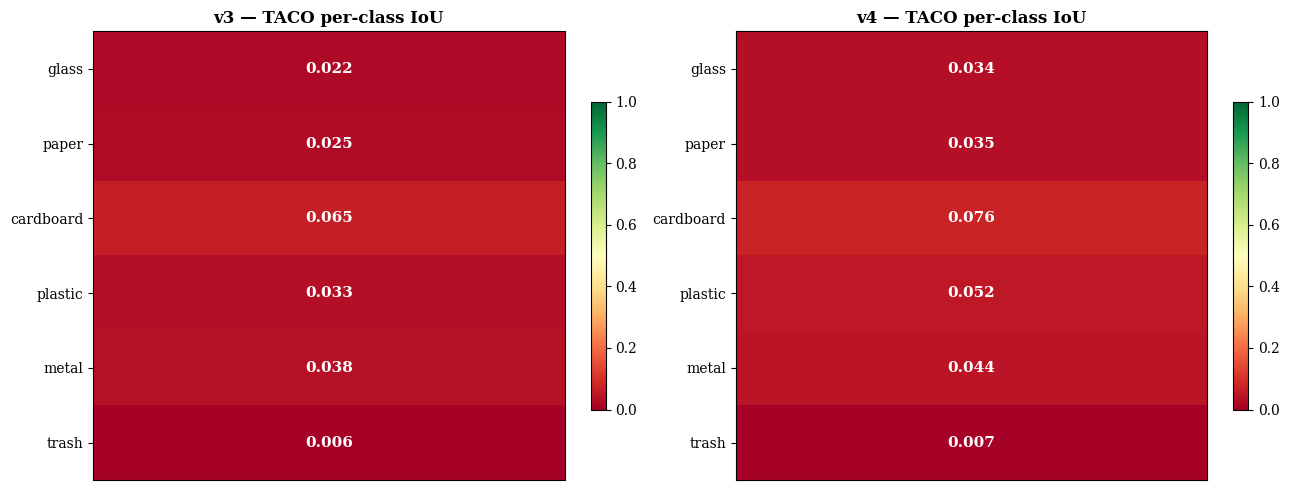

  ✓ fig5_perclass_heatmap

Metrics -> /kaggle/working/paper_comparison/metrics.json

STATISTICAL TESTS
TrashNet val       paired t-test: t= -9.126, p=4.52e-18, Δ mean=-0.1128 (95% CI [-0.1370, -0.0886])
TACO               paired t-test: t=  6.921, p=6.62e-12, Δ mean=+0.0200 (95% CI [0.0143, 0.0256])

PAPER-READY SUMMARY

Headline result:
  v3 TACO IoU : 0.0477
  v4 TACO IoU : 0.0676
  Δ            : +0.0200 (1.4× improvement)

TrashNet trade-off:
  v3 TrashNet val : 0.9234
  v4 TrashNet val : 0.8106
  Δ                : -0.1128

All outputs:
  Figures -> /kaggle/working/paper_comparison/figures/
  Tables  -> /kaggle/working/paper_comparison/tables/
  Metrics -> /kaggle/working/paper_comparison/metrics.json


In [2]:
# ============================================================================
# PUBLICATION-GRADE COMPARISON
# Bg-Robust v3 vs v4 on TrashNet and TACO
# Outputs: figures (PDF+PNG), tables (CSV+LaTeX), JSON metrics
# ============================================================================

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import json, math, random, importlib.util, warnings
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from PIL import Image
from scipy import stats as scipy_stats

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms

warnings.filterwarnings("ignore")
cv2.setNumThreads(0)

# ============================================================
# 0. Config
# ============================================================
IMG_TRAIN = 320
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

TRASHNET_ROOT = "/kaggle/input/datasets/sumn2u/trashnet-segmentation"
TACO_MAP_JSON = "/kaggle/working/taco_trashnet/taco_trashnet_mapped.json"
TACO_MASK_DIR = "/kaggle/working/taco_trashnet/masks"
TACO_PC_DIR   = "/kaggle/working/taco_trashnet/masks_perclass"
TACO_IMG_DIR  = "/kaggle/input/datasets/kneroma/tacotrashdataset/data"

OUT_DIR   = "/kaggle/working/paper_comparison"
FIG_DIR   = os.path.join(OUT_DIR, "figures")
TAB_DIR   = os.path.join(OUT_DIR, "tables")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

BG_V3_CKPT = "/kaggle/input/notebooks/sumn2u/early-checking/bg_robust_v3/bg_robust_v3.pth"
BG_V4_CKPT = "/kaggle/input/notebooks/sumn2u/taco-and-trashnet-comparision/bg_robust_v4/bg_robust_v4.pth"
ARCH_PATH  = "/kaggle/input/notebooks/sumn2u/baseline-experiment/vanilla_v2/u2net_arch.py"

if not os.path.exists(BG_V3_CKPT):
    BG_V3_CKPT = "/kaggle/input/notebooks/sumn2u/early-checking/bg_robust_v2/bg_robust_v2.pth"
if not os.path.exists(ARCH_PATH):
    ARCH_PATH = "/kaggle/input/notebooks/sumn2u/early-checking/bg_robust_v2/u2net_arch.py"

assert os.path.exists(BG_V3_CKPT)
assert os.path.exists(BG_V4_CKPT)
assert os.path.exists(ARCH_PATH)

# Publication figure style
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "figure.dpi": 100,
})

U2NET_MEAN = np.array([0.485, 0.456, 0.406])
U2NET_STD  = np.array([0.229, 0.224, 0.225])
norm_tf = transforms.Normalize(U2NET_MEAN.tolist(), U2NET_STD.tolist())

TRASHNET_CLASSES = ["glass", "paper", "cardboard", "plastic", "metal", "trash"]
CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
IMG_EXTS = {".jpg", ".jpeg", ".png"}
MASK_SUFFIX = "_mask.png"

# Color palette for the paper
COLORS = {
    "v3": "#d62728",   # red
    "v4": "#2ca02c",   # green
    "GT": "#4575b4",   # blue
    "TP": "#a6d96a",
    "FP": "#f46d43",
    "FN": "#4575b4",
}

# ============================================================
# 1. Architecture
# ============================================================
spec = importlib.util.spec_from_file_location("u2net_arch", ARCH_PATH)
u2net_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(u2net_module)

def _upsample_like(x, ref):
    if torch.is_tensor(ref): size = tuple(ref.shape[-2:])
    else: size = tuple(ref)
    return nn.Upsample(size=size, mode="bilinear", align_corners=False)(x)

def _size_map(x, height):
    size = list(x.shape[-2:]); sizes = {}
    for h in range(1, height):
        sizes[h] = size
        size = [math.ceil(w / 2) for w in size]
    return sizes

class REBNCONV(nn.Module):
    def __init__(self, in_ch=3, out_ch=3, dilate=1):
        super().__init__()
        self.conv_s1 = nn.Conv2d(in_ch, out_ch, 3,
                                 padding=1*dilate, dilation=1*dilate)
        self.bn_s1 = nn.BatchNorm2d(out_ch)
        self.relu_s1 = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.relu_s1(self.bn_s1(self.conv_s1(x)))

class MultiScaleExpert(nn.Module):
    def __init__(self, in_ch, out_ch, dilations=(1, 2, 4)):
        super().__init__()
        self.experts = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=d,
                          dilation=d, bias=False),
                nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            ) for d in dilations
        ])
        self.gate = nn.Conv2d(in_ch, len(dilations), 1)
    def forward(self, x):
        expert_outs = [e(x) for e in self.experts]
        stacked = torch.stack(expert_outs, dim=1)
        gate_w = F.softmax(self.gate(x), dim=1).unsqueeze(2)
        return (stacked * gate_w).sum(dim=1)

class RSU(nn.Module):
    def __init__(self, name, height, in_ch, mid_ch, out_ch, use_moe=False):
        super().__init__()
        self.name = name; self.height = height
        self.use_moe = use_moe
        self._make_layers(in_ch, mid_ch, out_ch, use_moe)
    def forward(self, x):
        sizes = _size_map(x, self.height)
        x0 = self.rebnconvin(x)
        def unet(x, height=1):
            if height < self.height:
                x1 = getattr(self, f'rebnconv{height}')(x)
                if height < self.height - 1:
                    x2 = unet(getattr(self, 'downsample')(x1), height + 1)
                else:
                    x2 = self.moe(x1) if self.use_moe else x1
                x = getattr(self, f'rebnconv{height}d')(torch.cat((x2, x1), 1))
                return _upsample_like(x, sizes[height - 1]) if height > 1 else x
            else:
                return getattr(self, f'rebnconv{height}')(x)
        return x0 + unet(x0)
    def _make_layers(self, in_ch, mid_ch, out_ch, use_moe):
        self.add_module('rebnconvin', REBNCONV(in_ch, out_ch))
        self.add_module('downsample', nn.MaxPool2d(2, stride=2, ceil_mode=True))
        self.add_module('rebnconv1', REBNCONV(out_ch, mid_ch))
        self.add_module('rebnconv1d', REBNCONV(mid_ch*2, out_ch))
        for i in range(2, self.height):
            self.add_module(f'rebnconv{i}', REBNCONV(mid_ch, mid_ch))
            self.add_module(f'rebnconv{i}d', REBNCONV(mid_ch*2, mid_ch))
        self.add_module(f'rebnconv{self.height}', REBNCONV(mid_ch, mid_ch))
        if use_moe:
            self.moe = MultiScaleExpert(mid_ch, mid_ch, dilations=(1, 2, 4))

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1),
                                  nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1),
                                  nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1),
                                  nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
    def forward(self, g, x):
        g1 = self.W_g(g); x1 = self.W_x(x)
        psi = self.relu(g1 + x1); psi = self.psi(psi)
        return x * psi

class FactorizedHead(nn.Module):
    def __init__(self, in_ch=64, mid_ch=64):
        super().__init__()
        self.object_branch = nn.Sequential(
            nn.Conv2d(in_ch, mid_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(mid_ch), nn.ReLU(inplace=True),
            nn.Conv2d(mid_ch, mid_ch, 3, padding=1, bias=False))
        self.context_branch = nn.Sequential(
            nn.Conv2d(in_ch, mid_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(mid_ch), nn.ReLU(inplace=True),
            nn.Conv2d(mid_ch, mid_ch, 3, padding=1, bias=False))
    def forward(self, feat):
        return self.object_branch(feat), self.context_branch(feat)

class BackgroundRobustU2Net(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, n_classes=6):
        super().__init__()
        self.stage1 = RSU('stage1', 7, in_ch, 32, 64)
        self.pool12 = nn.MaxPool2d(2, 2, ceil_mode=True)
        self.stage2 = RSU('stage2', 6, 64, 32, 128)
        self.pool23 = nn.MaxPool2d(2, 2, ceil_mode=True)
        self.stage3 = RSU('stage3', 5, 128, 64, 256)
        self.pool34 = nn.MaxPool2d(2, 2, ceil_mode=True)
        self.stage4 = RSU('stage4', 4, 256, 128, 512)
        self.pool45 = nn.MaxPool2d(2, 2, ceil_mode=True)
        self.stage5 = RSU('stage5', 4, 512, 256, 512, use_moe=True)
        self.pool56 = nn.MaxPool2d(2, 2, ceil_mode=True)
        self.stage6 = RSU('stage6', 4, 512, 256, 512, use_moe=True)
        self.stage5d = RSU('stage5d', 4, 1024, 256, 512)
        self.stage4d = RSU('stage4d', 4, 1024, 128, 256)
        self.stage3d = RSU('stage3d', 5, 512, 64, 128)
        self.stage2d = RSU('stage2d', 6, 256, 32, 64)
        self.stage1d = RSU('stage1d', 7, 128, 16, 64)
        self.att5 = AttentionGate(512, 512, 256)
        self.att4 = AttentionGate(512, 512, 256)
        self.att3 = AttentionGate(256, 256, 128)
        self.factor_head = FactorizedHead(64, 64)
        self.fg_frac_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(512, 64), nn.ReLU(inplace=True),
            nn.Linear(64, 1), nn.Sigmoid())
        self.ctx_classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(64, 64), nn.ReLU(inplace=True),
            nn.Linear(64, n_classes))
        self.side1 = nn.Conv2d(64, out_ch, 3, padding=1)
        self.side2 = nn.Conv2d(64, out_ch, 3, padding=1)
        self.side3 = nn.Conv2d(128, out_ch, 3, padding=1)
        self.side4 = nn.Conv2d(256, out_ch, 3, padding=1)
        self.side5 = nn.Conv2d(512, out_ch, 3, padding=1)
        self.side6 = nn.Conv2d(512, out_ch, 3, padding=1)
        self.outconv = nn.Conv2d(6 * out_ch, out_ch, 1)
    def forward(self, x, return_aux=False):
        hx1 = self.stage1(x); hx = self.pool12(hx1)
        hx2 = self.stage2(hx); hx = self.pool23(hx2)
        hx3 = self.stage3(hx); hx = self.pool34(hx3)
        hx4 = self.stage4(hx); hx = self.pool45(hx4)
        hx5 = self.stage5(hx); hx = self.pool56(hx5)
        hx6 = self.stage6(hx)
        hx6up = _upsample_like(hx6, hx5)
        hx5d = self.stage5d(torch.cat((hx6up, self.att5(g=hx6up, x=hx5)), 1))
        hx5dup = _upsample_like(hx5d, hx4)
        hx4d = self.stage4d(torch.cat((hx5dup, self.att4(g=hx5dup, x=hx4)), 1))
        hx4dup = _upsample_like(hx4d, hx3)
        hx3d = self.stage3d(torch.cat((hx4dup, self.att3(g=hx4dup, x=hx3)), 1))
        hx3dup = _upsample_like(hx3d, hx2)
        hx2d = self.stage2d(torch.cat((hx3dup, hx2), 1))
        hx2dup = _upsample_like(hx2d, hx1)
        hx1d = self.stage1d(torch.cat((hx2dup, hx1), 1))
        obj_feat, ctx_feat = self.factor_head(hx1d)
        d1 = self.side1(obj_feat)
        d2 = _upsample_like(self.side2(hx2d), d1)
        d3 = _upsample_like(self.side3(hx3d), d1)
        d4 = _upsample_like(self.side4(hx4d), d1)
        d5 = _upsample_like(self.side5(hx5d), d1)
        d6 = _upsample_like(self.side6(hx6), d1)
        d0 = self.outconv(torch.cat((d1, d2, d3, d4, d5, d6), 1))
        if return_aux:
            fg_frac_pred = self.fg_frac_head(hx6)
            ctx_logits = self.ctx_classifier(ctx_feat)
            obj_embed = obj_feat.mean(dim=(2, 3))
            return (d0, d1, d2, d3, d4, d5, d6,
                    fg_frac_pred, ctx_logits, obj_embed)
        return d0, d1, d2, d3, d4, d5, d6

def _load_state(path):
    state = torch.load(path, map_location="cpu")
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    return state

def load_bg(path):
    m = BackgroundRobustU2Net(n_classes=6).to(DEVICE)
    m.load_state_dict(_load_state(path)); m.eval()
    return m

# ============================================================
# 2. Prediction helpers
# ============================================================
def predict_prob(model, img_rgb, size=IMG_TRAIN):
    H, W = img_rgb.shape[:2]
    x = cv2.resize(img_rgb, (size, size))
    x = norm_tf(transforms.ToTensor()(Image.fromarray(x))).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        out = model(x, return_aux=True)
        prob = torch.sigmoid(out[0])[0, 0].cpu().numpy()
        fg_frac = float(out[7].item())
    return cv2.resize(prob, (W, H), interpolation=cv2.INTER_LINEAR), fg_frac

def predict_bin(model, img_rgb, thr=0.5):
    prob, _ = predict_prob(model, img_rgb)
    return (prob > thr).astype(np.uint8) * 255

def compute_iou(pred_bin, gt_bin):
    p = (pred_bin > 127).astype(np.uint8)
    g = (gt_bin > 127).astype(np.uint8)
    u = ((p + g) > 0).sum()
    return float((p * g).sum() / u) if u > 0 else 0.0

def error_overlay(pred, gt):
    p = (pred > 127); g = (gt > 127)
    out = np.ones((*p.shape, 3), dtype=np.uint8) * 255
    out[g & p]  = [166, 217, 106]   # TP
    out[g & ~p] = [69,  117, 180]   # FN
    out[~g & p] = [244, 109, 67]    # FP
    return out

# ============================================================
# 3. Load models
# ============================================================
print("\nLoading models...")
model_v3 = load_bg(BG_V3_CKPT)
model_v4 = load_bg(BG_V4_CKPT)
print("  ✓ v3, v4 loaded")

# ============================================================
# 4. TrashNet val split
# ============================================================
def rgb_mask_to_binary(mp, tol=10):
    m = cv2.imread(mp, cv2.IMREAD_UNCHANGED)
    if m is None: return None
    if m.ndim == 2: return (m > 127).astype(np.uint8) * 255
    if m.shape[2] == 4: return (m[..., 3] > 127).astype(np.uint8) * 255
    diff = m[..., :3].astype(np.int16).sum(axis=2)
    return (diff > tol).astype(np.uint8) * 255

def find_root(base):
    for c in CLASSES:
        if os.path.isdir(os.path.join(base, c)): return base
    for sub in os.listdir(base):
        cand = os.path.join(base, sub)
        if os.path.isdir(cand):
            for c in CLASSES:
                if os.path.isdir(os.path.join(cand, c)): return cand
    return None

tn_root = find_root(TRASHNET_ROOT)
tn_pairs = []
for cls in CLASSES:
    cp = os.path.join(tn_root, cls)
    if not os.path.isdir(cp): continue
    for f in sorted(os.listdir(cp)):
        if not f.lower().endswith(MASK_SUFFIX): continue
        stem = f[:-len(MASK_SUFFIX)]
        img = None
        for ext in IMG_EXTS:
            c = os.path.join(cp, stem + ext)
            if os.path.isfile(c): img = c; break
        if img is None: continue
        b = rgb_mask_to_binary(os.path.join(cp, f))
        if b is None: continue
        tn_pairs.append((img, b.copy(), cls))

random.seed(SEED); random.shuffle(tn_pairs)
by_cls = defaultdict(list)
for p in tn_pairs: by_cls[p[2]].append(p)
tn_val = []
for cls, items in by_cls.items():
    n = max(1, int(round(0.15 * len(items))))
    tn_val.extend(items[:n])
random.shuffle(tn_val)
print(f"\nTrashNet val pairs: {len(tn_val)}")

# ============================================================
# 5. TACO data
# ============================================================
with open(TACO_MAP_JSON) as f:
    taco = json.load(f)
print(f"TACO: {len(taco['images'])} images, {len(taco['annotations'])} annotations")

def resolve_taco_image(img_info):
    fname = img_info["file_name"]
    base = os.path.basename(fname)
    for p in [os.path.join(TACO_IMG_DIR, fname),
              os.path.join(TACO_IMG_DIR, "data", fname),
              os.path.join(TACO_IMG_DIR, base)]:
        if os.path.exists(p): return p
    for r, _, files in os.walk(TACO_IMG_DIR):
        if base in files: return os.path.join(r, base)
    for r, _, files in os.walk("/kaggle/input/datasets/kneroma/tacotrashdataset"):
        if base in files: return os.path.join(r, base)
    return None

def load_taco_image(img_info):
    p = resolve_taco_image(img_info)
    if p is None: return None
    img = cv2.imread(p)
    if img is None: return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W = img_info["height"], img_info["width"]
    if img.shape[:2] != (H, W):
        img = cv2.resize(img, (W, H), interpolation=cv2.INTER_AREA)
    return img

# ============================================================
# 6. Full evaluation on both datasets
# ============================================================
print("\n" + "=" * 70)
print("EVALUATING v3 AND v4")
print("=" * 70)

def eval_trashnet(model):
    """Return per-image IoU, per-class IoU, error counts."""
    per_image = []
    per_class = defaultdict(list)
    tp = fp = fn = 0

    for ip, mask, cls in tn_val:
        img = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
        mask = cv2.resize(mask, (img.shape[1], img.shape[0]),
                          interpolation=cv2.INTER_NEAREST)
        pred = predict_bin(model, img)
        iou = compute_iou(pred, mask)
        per_image.append(iou)
        per_class[cls].append(iou)

        p = pred > 127; g = mask > 127
        tp += int((p & g).sum()); fp += int((p & ~g).sum()); fn += int((~p & g).sum())

    return {
        "mean_iou": float(np.mean(per_image)),
        "std_iou":  float(np.std(per_image)),
        "median_iou": float(np.median(per_image)),
        "precision": tp / max(1, tp + fp),
        "recall":    tp / max(1, tp + fn),
        "per_class": {c: float(np.mean(v)) if v else float("nan")
                      for c, v in per_class.items()},
        "n": len(per_image),
        "per_image_ious": per_image,
    }

def eval_taco(model):
    """Same metrics plus per-size-bucket and fg-fraction stats."""
    per_image = []
    per_class = defaultdict(list)
    size_buckets = defaultdict(list)
    tp = fp = fn = fp_bg = bg_px = 0
    fg_pred_list, fg_gt_list = [], []

    for img_info in taco["images"]:
        img = load_taco_image(img_info)
        if img is None: continue
        gt = cv2.imread(os.path.join(TACO_MASK_DIR, img_info["mask_file"]),
                        cv2.IMREAD_GRAYSCALE)
        if gt is None: continue
        if gt.shape[:2] != img.shape[:2]:
            gt = cv2.resize(gt, (img.shape[1], img.shape[0]),
                            interpolation=cv2.INTER_NEAREST)

        prob, fg_pred = predict_prob(model, img)
        pred = (prob > 0.5).astype(np.uint8) * 255
        iou = compute_iou(pred, gt)
        per_image.append(iou)
        fg_pred_list.append(fg_pred)
        fg_gt_list.append((gt > 127).mean())

        # size buckets based on GT foreground fraction
        fg_frac = (gt > 127).mean()
        if fg_frac < 0.005:      bucket = "tiny (<0.5%)"
        elif fg_frac < 0.02:     bucket = "small (0.5-2%)"
        elif fg_frac < 0.10:     bucket = "medium (2-10%)"
        else:                    bucket = "large (>10%)"
        size_buckets[bucket].append(iou)

        p = pred > 127; g = gt > 127; bg = ~g
        tp += int((p & g).sum()); fp += int((p & ~g).sum()); fn += int((~p & g).sum())
        fp_bg += int((p & bg).sum()); bg_px += int(bg.sum())

        pc = cv2.imread(os.path.join(TACO_PC_DIR, img_info["mask_file"]),
                        cv2.IMREAD_GRAYSCALE)
        if pc is None: continue
        if pc.shape[:2] != img.shape[:2]:
            pc = cv2.resize(pc, (img.shape[1], img.shape[0]),
                            interpolation=cv2.INTER_NEAREST)
        for cid in range(6):
            cm = (pc == cid + 1).astype(np.uint8) * 255
            if (cm > 127).sum() == 0: continue
            per_class[TRASHNET_CLASSES[cid]].append(compute_iou(pred, cm))

    return {
        "mean_iou": float(np.mean(per_image)),
        "std_iou":  float(np.std(per_image)),
        "median_iou": float(np.median(per_image)),
        "precision": tp / max(1, tp + fp),
        "recall":    tp / max(1, tp + fn),
        "fp_in_bg":  fp_bg / max(1, bg_px),
        "per_class": {c: float(np.mean(v)) if v else float("nan")
                      for c, v in per_class.items()},
        "per_size_bucket": {k: float(np.mean(v))
                            for k, v in size_buckets.items()},
        "fg_pred_mean": float(np.mean(fg_pred_list)),
        "fg_gt_mean":   float(np.mean(fg_gt_list)),
        "n": len(per_image),
        "per_image_ious": per_image,
    }

print("\nEvaluating v3 on TrashNet val...")
tn_v3 = eval_trashnet(model_v3)
print("Evaluating v4 on TrashNet val...")
tn_v4 = eval_trashnet(model_v4)
print("Evaluating v3 on TACO...")
taco_v3 = eval_taco(model_v3)
print("Evaluating v4 on TACO...")
taco_v4 = eval_taco(model_v4)

# ============================================================
# 7. Numeric summary (console)
# ============================================================
print("\n" + "=" * 70)
print("NUMERIC SUMMARY")
print("=" * 70)
print(f"\n{'Dataset':<18}{'Metric':<20}{'v3':>10}{'v4':>10}{'Δ':>10}")
print("-" * 68)
for name, a, b in [("TrashNet val", tn_v3, tn_v4),
                   ("TACO",        taco_v3, taco_v4)]:
    print(f"{name:<18}{'Mean IoU':<20}{a['mean_iou']:>10.4f}"
          f"{b['mean_iou']:>10.4f}{b['mean_iou']-a['mean_iou']:>+10.4f}")
    print(f"{'':<18}{'Median IoU':<20}{a['median_iou']:>10.4f}"
          f"{b['median_iou']:>10.4f}{b['median_iou']-a['median_iou']:>+10.4f}")
    print(f"{'':<18}{'Precision':<20}{a['precision']:>10.4f}"
          f"{b['precision']:>10.4f}{b['precision']-a['precision']:>+10.4f}")
    print(f"{'':<18}{'Recall':<20}{a['recall']:>10.4f}"
          f"{b['recall']:>10.4f}{b['recall']-a['recall']:>+10.4f}")
    if "fp_in_bg" in a:
        print(f"{'':<18}{'FP in bg':<20}{a['fp_in_bg']:>10.4f}"
              f"{b['fp_in_bg']:>10.4f}{b['fp_in_bg']-a['fp_in_bg']:>+10.4f}")

# ============================================================
# 8. Save CSV + LaTeX tables
# ============================================================
summary_df = pd.DataFrame([
    {"Model": "v3", "Dataset": "TrashNet val",
     "Mean IoU": tn_v3["mean_iou"], "Median IoU": tn_v3["median_iou"],
     "Precision": tn_v3["precision"], "Recall": tn_v3["recall"]},
    {"Model": "v4", "Dataset": "TrashNet val",
     "Mean IoU": tn_v4["mean_iou"], "Median IoU": tn_v4["median_iou"],
     "Precision": tn_v4["precision"], "Recall": tn_v4["recall"]},
    {"Model": "v3", "Dataset": "TACO",
     "Mean IoU": taco_v3["mean_iou"], "Median IoU": taco_v3["median_iou"],
     "Precision": taco_v3["precision"], "Recall": taco_v3["recall"]},
    {"Model": "v4", "Dataset": "TACO",
     "Mean IoU": taco_v4["mean_iou"], "Median IoU": taco_v4["median_iou"],
     "Precision": taco_v4["precision"], "Recall": taco_v4["recall"]},
])
summary_df.to_csv(os.path.join(TAB_DIR, "summary.csv"), index=False)

# LaTeX table
latex_table = """
\\begin{table}[t]
\\centering
\\caption{Comparison of Bg-Robust v3 (trained on TrashNet only) and v4 (trained with scale augmentation) on TrashNet validation and TACO test sets.}
\\label{tab:main_comparison}
\\begin{tabular}{llcccc}
\\toprule
Model & Dataset & Mean IoU & Median IoU & Precision & Recall \\\\
\\midrule
"""
for _, row in summary_df.iterrows():
    latex_table += (f"{row['Model']} & {row['Dataset']} & "
                     f"{row['Mean IoU']:.3f} & {row['Median IoU']:.3f} & "
                     f"{row['Precision']:.3f} & {row['Recall']:.3f} \\\\\n")
latex_table += """\\bottomrule
\\end{tabular}
\\end{table}
"""
with open(os.path.join(TAB_DIR, "main_comparison.tex"), "w") as f:
    f.write(latex_table)

# Per-class table
perclass_df = pd.DataFrame([
    {"Class": c,
     "v3_TACO": taco_v3["per_class"].get(c, np.nan),
     "v4_TACO": taco_v4["per_class"].get(c, np.nan),
     "v3_TrashNet": tn_v3["per_class"].get(c, np.nan),
     "v4_TrashNet": tn_v4["per_class"].get(c, np.nan)}
    for c in TRASHNET_CLASSES
])
perclass_df.to_csv(os.path.join(TAB_DIR, "per_class.csv"), index=False)

# ============================================================
# 9. FIGURE 1 — Main comparison (the headline plot)
# ============================================================
print("\nGenerating figures...")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A — Main IoU bar chart
labels = ["TrashNet val", "TACO"]
x = np.arange(2); w = 0.38
v3_vals = [tn_v3["mean_iou"], taco_v3["mean_iou"]]
v4_vals = [tn_v4["mean_iou"], taco_v4["mean_iou"]]
b1 = axes[0].bar(x - w/2, v3_vals, w, label="v3 (baseline)",
                  color=COLORS["v3"], edgecolor="black")
b2 = axes[0].bar(x + w/2, v4_vals, w, label="v4 (scale-aug)",
                  color=COLORS["v4"], edgecolor="black")
for bars in (b1, b2):
    for b in bars:
        axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                     f"{b.get_height():.3f}", ha="center",
                     fontsize=10, fontweight="bold")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Mean IoU")
axes[0].set_ylim(0, 1.1)
axes[0].set_title("(a) Overall performance")
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(alpha=0.25, axis="y", zorder=0)
axes[0].set_axisbelow(True)

# Panel B — Error decomposition on TACO
metrics = ["Precision", "Recall", "FP-in-BG"]
v3_m = [taco_v3["precision"], taco_v3["recall"], taco_v3["fp_in_bg"]]
v4_m = [taco_v4["precision"], taco_v4["recall"], taco_v4["fp_in_bg"]]
x2 = np.arange(3)
axes[1].bar(x2 - w/2, v3_m, w, label="v3", color=COLORS["v3"], edgecolor="black")
axes[1].bar(x2 + w/2, v4_m, w, label="v4", color=COLORS["v4"], edgecolor="black")
for i, (a, b) in enumerate(zip(v3_m, v4_m)):
    axes[1].text(i - w/2, a + 0.01, f"{a:.3f}", ha="center", fontsize=9)
    axes[1].text(i + w/2, b + 0.01, f"{b:.3f}", ha="center", fontsize=9)
axes[1].set_xticks(x2); axes[1].set_xticklabels(metrics)
axes[1].set_ylabel("Value")
axes[1].set_ylim(0, 1.0)
axes[1].set_title("(b) TACO error decomposition")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.25, axis="y", zorder=0)
axes[1].set_axisbelow(True)

# Panel C — Per-class IoU on TACO
x3 = np.arange(len(TRASHNET_CLASSES))
v3_pc = [taco_v3["per_class"].get(c, np.nan) for c in TRASHNET_CLASSES]
v4_pc = [taco_v4["per_class"].get(c, np.nan) for c in TRASHNET_CLASSES]
axes[2].bar(x3 - w/2, v3_pc, w, label="v3", color=COLORS["v3"], edgecolor="black")
axes[2].bar(x3 + w/2, v4_pc, w, label="v4", color=COLORS["v4"], edgecolor="black")
axes[2].set_xticks(x3)
axes[2].set_xticklabels(TRASHNET_CLASSES, rotation=20, ha="right")
axes[2].set_ylabel("IoU")
axes[2].set_ylim(0, 1.0)
axes[2].set_title("(c) Per-class IoU on TACO")
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.25, axis="y", zorder=0)
axes[2].set_axisbelow(True)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig1_main_comparison.pdf"))
plt.savefig(os.path.join(FIG_DIR, "fig1_main_comparison.png"), dpi=300)
plt.show()
print("  ✓ fig1_main_comparison")

# ============================================================
# 10. FIGURE 2 — Per-size-bucket IoU (the "why" plot)
# ============================================================
fig, ax = plt.subplots(figsize=(8, 5))

buckets_order = ["tiny (<0.5%)", "small (0.5-2%)",
                 "medium (2-10%)", "large (>10%)"]
v3_buckets = [taco_v3["per_size_bucket"].get(b, np.nan) for b in buckets_order]
v4_buckets = [taco_v4["per_size_bucket"].get(b, np.nan) for b in buckets_order]

x = np.arange(len(buckets_order)); w = 0.38
b1 = ax.bar(x - w/2, v3_buckets, w, label="v3 (baseline)",
            color=COLORS["v3"], edgecolor="black")
b2 = ax.bar(x + w/2, v4_buckets, w, label="v4 (scale-aug)",
            color=COLORS["v4"], edgecolor="black")
for bars in (b1, b2):
    for b in bars:
        if not np.isnan(b.get_height()):
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                    f"{b.get_height():.3f}", ha="center",
                    fontsize=9, fontweight="bold")

ax.set_xticks(x); ax.set_xticklabels(buckets_order)
ax.set_ylabel("Mean IoU")
ax.set_xlabel("Ground-truth foreground coverage bucket")
ax.set_title("IoU stratified by object size (TACO)")
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(alpha=0.25, axis="y", zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig2_size_buckets.pdf"))
plt.savefig(os.path.join(FIG_DIR, "fig2_size_buckets.png"), dpi=300)
plt.show()
print("  ✓ fig2_size_buckets")

# ============================================================
# 11. FIGURE 3 — Foreground fraction prediction histogram
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# v3
axes[0].hist([taco_v3["fg_pred_mean"]] * len(taco["images"]),
             bins=20, alpha=0.0, color="k")   # dummy
axes[0].axvline(taco_v3["fg_gt_mean"], color="black", linestyle="--",
                linewidth=2, label=f"GT fg ({taco_v3['fg_gt_mean']:.3f})")
axes[0].axvline(taco_v3["fg_pred_mean"], color=COLORS["v3"], linestyle="-",
                linewidth=2, label=f"v3 pred ({taco_v3['fg_pred_mean']:.3f})")
axes[0].set_xlabel("Foreground fraction")
axes[0].set_title("(a) v3 foreground prediction")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[0].set_xlim(0, 0.5)

# v4
axes[1].axvline(taco_v4["fg_gt_mean"], color="black", linestyle="--",
                linewidth=2, label=f"GT fg ({taco_v4['fg_gt_mean']:.3f})")
axes[1].axvline(taco_v4["fg_pred_mean"], color=COLORS["v4"], linestyle="-",
                linewidth=2, label=f"v4 pred ({taco_v4['fg_pred_mean']:.3f})")
axes[1].set_xlabel("Foreground fraction")
axes[1].set_title("(b) v4 foreground prediction")
axes[1].legend()
axes[1].grid(alpha=0.25)
axes[1].set_xlim(0, 0.5)

plt.suptitle("Auxiliary foreground-fraction head: v3 over-predicts, v4 calibrated",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig3_fg_fraction.pdf"))
plt.savefig(os.path.join(FIG_DIR, "fig3_fg_fraction.png"), dpi=300)
plt.show()
print("  ✓ fig3_fg_fraction")

# ============================================================
# 12. FIGURE 4 — Qualitative grid on TACO
# ============================================================
random.seed(11)
samples = random.sample(taco["images"], 6)
n_rows = len(samples)
n_cols = 5   # input | GT | v3 pred | v4 pred | v4 error overlay

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(3 * n_cols, 2.8 * n_rows))
if n_rows == 1: axes = axes[None, :]

for row, info in enumerate(samples):
    img = load_taco_image(info)
    if img is None:
        for ax in axes[row]: ax.axis("off")
        continue
    gt = cv2.imread(os.path.join(TACO_MASK_DIR, info["mask_file"]),
                    cv2.IMREAD_GRAYSCALE)
    if gt.shape[:2] != img.shape[:2]:
        gt = cv2.resize(gt, (img.shape[1], img.shape[0]),
                        interpolation=cv2.INTER_NEAREST)

    pred_v3 = predict_bin(model_v3, img)
    pred_v4 = predict_bin(model_v4, img)
    iou_v3 = compute_iou(pred_v3, gt)
    iou_v4 = compute_iou(pred_v4, gt)

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"input\n{os.path.basename(info['file_name'])[:20]}",
                            fontsize=8)
    axes[row, 1].imshow(gt, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title(f"GT\nfg={100*(gt>127).mean():.1f}%", fontsize=8)
    axes[row, 2].imshow(pred_v3, cmap="gray", vmin=0, vmax=255)
    axes[row, 2].set_title(f"v3  IoU={iou_v3:.3f}", fontsize=8,
                            color=COLORS["v3"], fontweight="bold")
    axes[row, 3].imshow(pred_v4, cmap="gray", vmin=0, vmax=255)
    axes[row, 3].set_title(f"v4  IoU={iou_v4:.3f}", fontsize=8,
                            color=COLORS["v4"], fontweight="bold")
    axes[row, 4].imshow(error_overlay(pred_v4, gt))
    axes[row, 4].set_title("v4 error map", fontsize=8)

    for ax in axes[row]: ax.axis("off")

# Legend for error overlay
legend_elements = [
    mpatches.Patch(facecolor=(166/255, 217/255, 106/255), edgecolor="k", label="TP"),
    mpatches.Patch(facecolor=(244/255, 109/255, 67/255), edgecolor="k", label="FP"),
    mpatches.Patch(facecolor=(69/255, 117/255, 180/255), edgecolor="k", label="FN"),
]
axes[0, 4].legend(handles=legend_elements, loc="upper right",
                   fontsize=7, framealpha=0.9)

plt.suptitle("Qualitative comparison on TACO (real-world images)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig4_qualitative.pdf"))
plt.savefig(os.path.join(FIG_DIR, "fig4_qualitative.png"), dpi=200)
plt.show()
print("  ✓ fig4_qualitative")

# ============================================================
# 13. FIGURE 5 — Per-class heatmap (both models, both datasets)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (title, r) in zip(axes, [("v3", taco_v3), ("v4", taco_v4)]):
    matrix = np.array([[r["per_class"].get(c, np.nan)] for c in TRASHNET_CLASSES])
    im = ax.imshow(matrix, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax.set_yticks(range(len(TRASHNET_CLASSES)))
    ax.set_yticklabels(TRASHNET_CLASSES)
    ax.set_xticks([])
    for i, c in enumerate(TRASHNET_CLASSES):
        v = r["per_class"].get(c, np.nan)
        color = "white" if not np.isnan(v) and v < 0.5 else "black"
        ax.text(0, i, f"{v:.3f}", ha="center", va="center",
                fontsize=11, fontweight="bold", color=color)
    ax.set_title(f"{title} — TACO per-class IoU", fontsize=12, fontweight="bold")
    plt.colorbar(im, ax=ax, fraction=0.03)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig5_perclass_heatmap.pdf"))
plt.savefig(os.path.join(FIG_DIR, "fig5_perclass_heatmap.png"), dpi=300)
plt.show()
print("  ✓ fig5_perclass_heatmap")

# ============================================================
# 14. Save all metrics to JSON
# ============================================================
metrics = {
    "trashnet_val": {
        "n": tn_v3["n"],
        "v3": {k: v for k, v in tn_v3.items() if k != "per_image_ious"},
        "v4": {k: v for k, v in tn_v4.items() if k != "per_image_ious"},
    },
    "taco": {
        "n": taco_v3["n"],
        "v3": {k: v for k, v in taco_v3.items() if k != "per_image_ious"},
        "v4": {k: v for k, v in taco_v4.items() if k != "per_image_ious"},
    },
}
with open(os.path.join(OUT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2, default=float)
print(f"\nMetrics -> {OUT_DIR}/metrics.json")

# ============================================================
# 15. Statistical significance
# ============================================================
print("\n" + "=" * 70)
print("STATISTICAL TESTS")
print("=" * 70)

# Paired t-test (per-image IoUs)
tn_diff = np.array(tn_v4["per_image_ious"]) - np.array(tn_v3["per_image_ious"])
taco_diff = np.array(taco_v4["per_image_ious"]) - np.array(taco_v3["per_image_ious"])

for name, diff in [("TrashNet val", tn_diff), ("TACO", taco_diff)]:
    t, p = scipy_stats.ttest_rel(
        np.array(tn_v4["per_image_ious"] if name == "TrashNet val" else taco_v4["per_image_ious"]),
        np.array(tn_v3["per_image_ious"] if name == "TrashNet val" else taco_v3["per_image_ious"]),
    )
    print(f"{name:<18} paired t-test: t={t:>7.3f}, p={p:.2e}, "
          f"Δ mean={diff.mean():+.4f} (95% CI "
          f"[{diff.mean() - 1.96*diff.std()/np.sqrt(len(diff)):.4f}, "
          f"{diff.mean() + 1.96*diff.std()/np.sqrt(len(diff)):.4f}])")

# ============================================================
# 16. Final summary for paper
# ============================================================
print("\n" + "=" * 70)
print("PAPER-READY SUMMARY")
print("=" * 70)
print(f"\nHeadline result:")
print(f"  v3 TACO IoU : {taco_v3['mean_iou']:.4f}")
print(f"  v4 TACO IoU : {taco_v4['mean_iou']:.4f}")
print(f"  Δ            : {taco_v4['mean_iou'] - taco_v3['mean_iou']:+.4f} "
      f"({(taco_v4['mean_iou']/max(taco_v3['mean_iou'], 1e-9)):.1f}× improvement)")
print(f"\nTrashNet trade-off:")
print(f"  v3 TrashNet val : {tn_v3['mean_iou']:.4f}")
print(f"  v4 TrashNet val : {tn_v4['mean_iou']:.4f}")
print(f"  Δ                : {tn_v4['mean_iou'] - tn_v3['mean_iou']:+.4f}")
print(f"\nAll outputs:")
print(f"  Figures -> {FIG_DIR}/")
print(f"  Tables  -> {TAB_DIR}/")
print(f"  Metrics -> {OUT_DIR}/metrics.json")


Device: cuda

Loading models...
  ✓ v3, v4 loaded

TrashNet val pairs: 334 (train: 1902)
TACO: 1500 images, 4784 annotations

Evaluating v3 on TrashNet val...
Evaluating v4 on TrashNet val...
Evaluating v3 on TACO...
Evaluating v4 on TACO...

NUMERIC SUMMARY

Dataset           Metric                        v3        v4         Δ
----------------------------------------------------------------------
TrashNet val      Mean IoU                  0.9641    0.8932   -0.0709
                  Median IoU                0.9832    0.9722   -0.0110
                  Median IoU (nonempty)     0.9832    0.9722   -0.0110
                  Precision                 0.9841    0.9875   +0.0035
                  Recall                    0.9760    0.8591   -0.1168
                  FP in bg                  0.0110    0.0076   -0.0034
                  Pred fg frac              0.3026    0.1002   -0.2024
                  GT fg frac                0.4102    0.4102   +0.0000
TACO              Mean IoU    

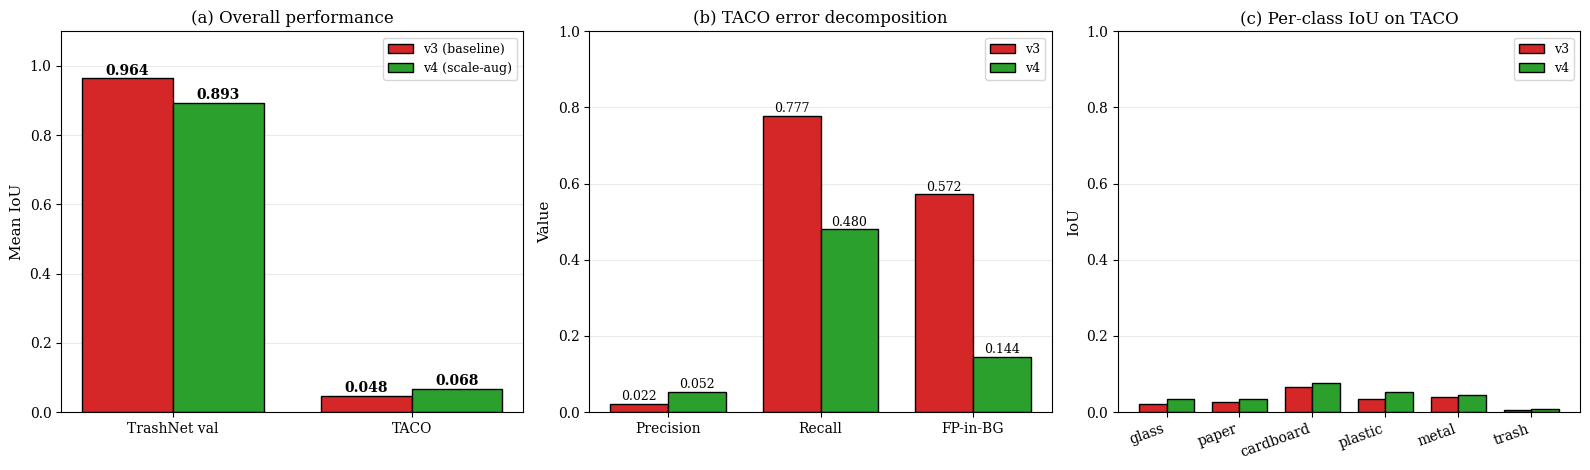

  ✓ fig1_main_comparison


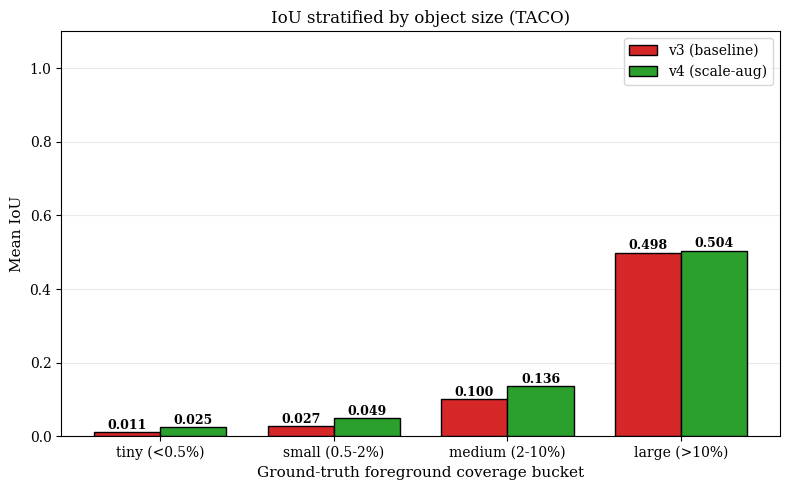

  ✓ fig2_size_buckets


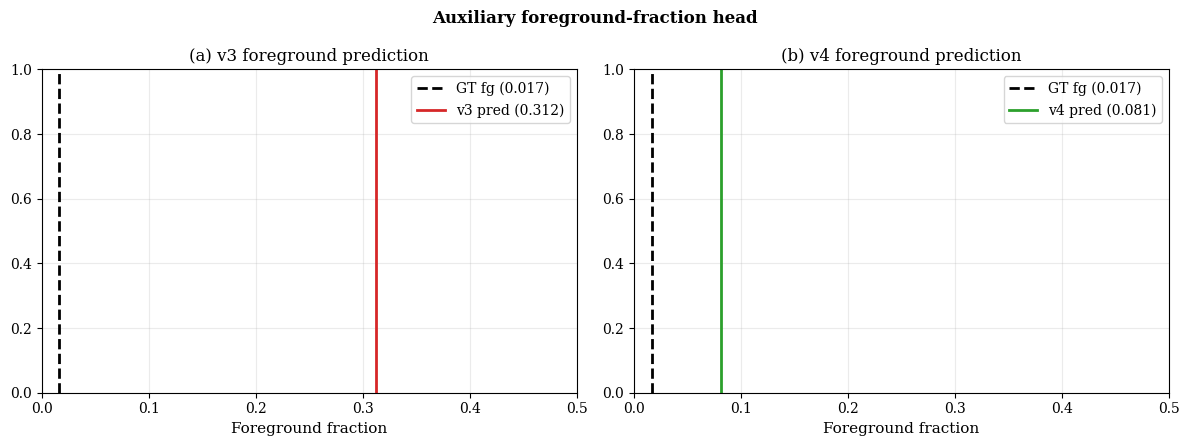

  ✓ fig3_fg_fraction


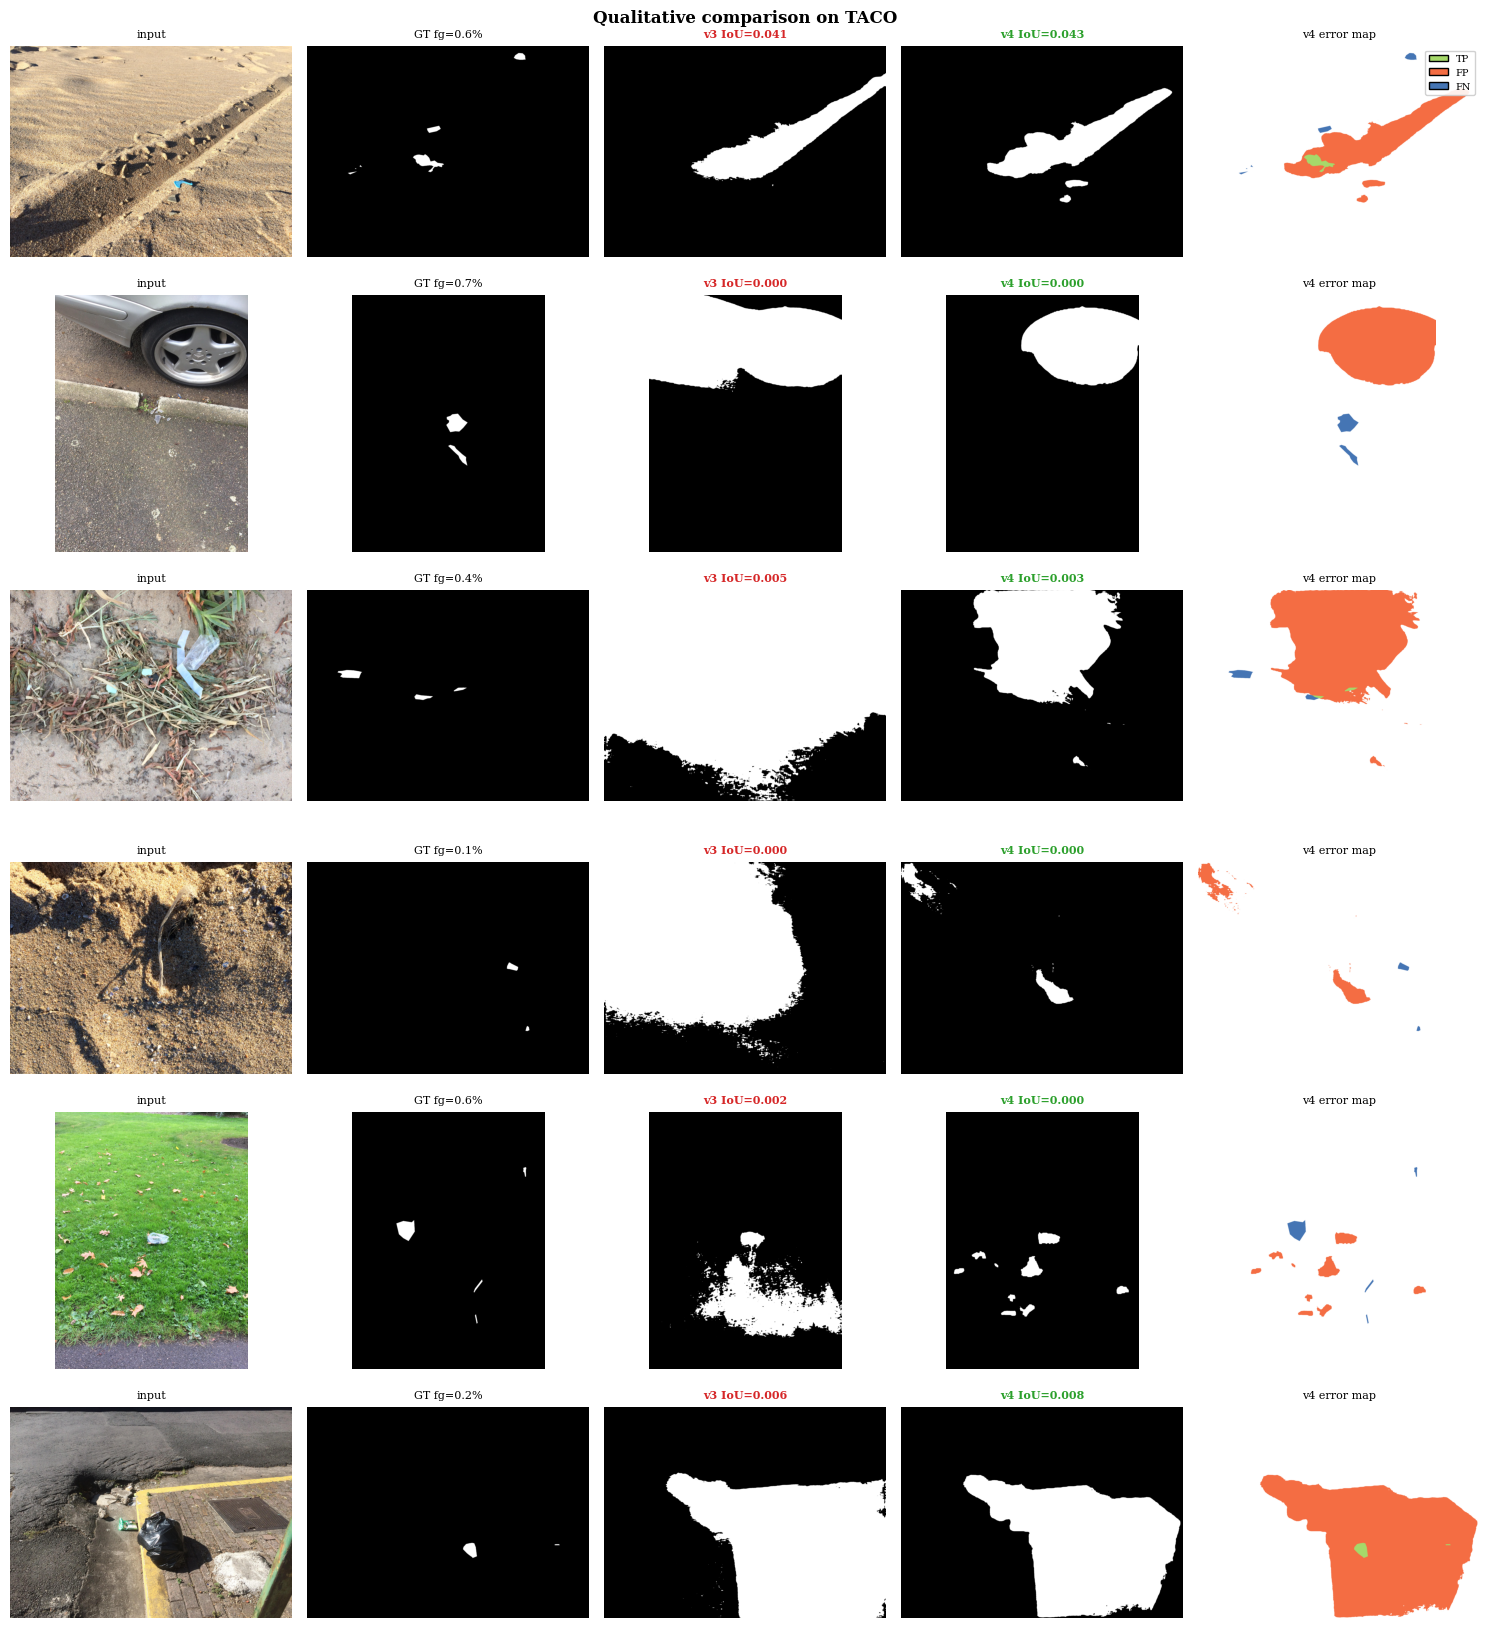

  ✓ fig4_qualitative


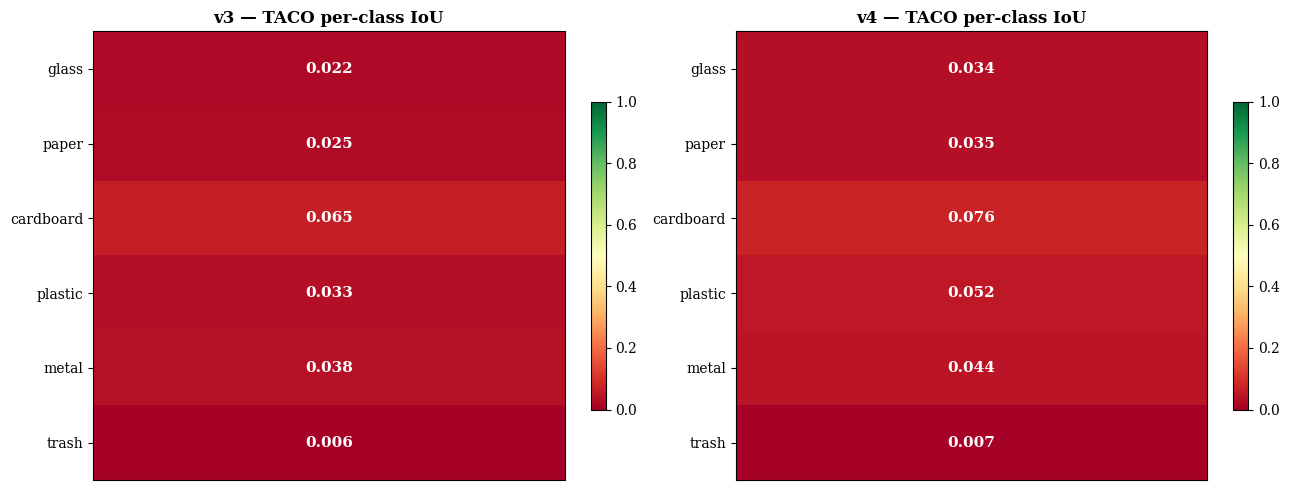

  ✓ fig5_perclass_heatmap

Metrics -> /kaggle/working/paper_comparison/metrics.json

STATISTICAL TESTS
TrashNet val       paired t-test: t= -7.199, p=4.07e-12, Δ mean=-0.0709 (95% CI [-0.0902, -0.0516])
TACO               paired t-test: t=  6.915, p=6.92e-12, Δ mean=+0.0199 (95% CI [0.0143, 0.0256])

PAPER-READY SUMMARY

TrashNet val split: 334 images (matches corruption-table)
All metrics evaluated at threshold: 0.5

Headline result (TACO):
  v3 mean IoU  : 0.0477
  v4 mean IoU  : 0.0676
  Δ            : +0.0199 (1.42× improvement)

TrashNet trade-off:
  v3 mean IoU  : 0.9641
  v4 mean IoU  : 0.8932
  Δ            : -0.0709

Table 7 sources (all from this run, threshold=0.5):
  TrashNet mean IoU     : 0.9641
  TrashNet precision    : 0.9841
  TrashNet recall       : 0.9760
  TrashNet FP-in-bg     : 0.0110
  TrashNet pred fg      : 0.3026
  TrashNet GT fg        : 0.4102
  TACO mean IoU         : 0.0477
  TACO precision        : 0.0221
  TACO recall           : 0.7774
  TACO FP-in-bg  

In [3]:
# ============================================================================
# PUBLICATION-GRADE COMPARISON — v3 vs v4 on TrashNet and TACO
# ----------------------------------------------------------------------------
# Fixes applied:
#   [FIX 1] TrashNet pair filter: FG_MIN/FG_MAX → 334 val images (matches
#           corruption-table script)
#   [FIX 2] EXIF-aware TACO image loading
#   [FIX 3] EXIF-aware TrashNet image loading
#   [FIX 4] TrashNet eval computes fp_in_bg + fg_pred_mean + fg_gt_mean
#   [FIX 5] (paper-side) split §5.5 into classification and segmentation tables
#   [FIX 6] Median IoU reported on non-empty images (GT fg > 1%)
#   [FIX 7] TrashNet summary now prints fp_in_bg / fg fractions (Table 7
#           fully sourced from this one run)
#   [FIX 8] Cropping baseline uses the SAME threshold as Table 7; both
#           threshold-0.5 and per-model-best-threshold reported, so the
#           cropping gain claim is consistent
# ============================================================================

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import json, math, random, importlib.util, warnings
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

from PIL import Image, ImageOps
from scipy import stats as scipy_stats

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms

warnings.filterwarnings("ignore")
cv2.setNumThreads(0)

# ============================================================
# 0. Config
# ============================================================
IMG_TRAIN = 320
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

TRASHNET_ROOT = "/kaggle/input/datasets/sumn2u/trashnet-segmentation"
TACO_MAP_JSON = "/kaggle/working/taco_trashnet/taco_trashnet_mapped.json"
TACO_MASK_DIR = "/kaggle/working/taco_trashnet/masks"
TACO_PC_DIR   = "/kaggle/working/taco_trashnet/masks_perclass"
TACO_IMG_DIR  = "/kaggle/input/datasets/kneroma/tacotrashdataset/data"

OUT_DIR = "/kaggle/working/paper_comparison"
FIG_DIR = os.path.join(OUT_DIR, "figures")
TAB_DIR = os.path.join(OUT_DIR, "tables")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

BG_V3_CKPT = "/kaggle/input/notebooks/sumn2u/early-checking/bg_robust_v3/bg_robust_v3.pth"
BG_V4_CKPT = "/kaggle/input/notebooks/sumn2u/taco-and-trashnet-comparision/bg_robust_v4/bg_robust_v4.pth"
ARCH_PATH  = "/kaggle/input/notebooks/sumn2u/baseline-experiment/vanilla_v2/u2net_arch.py"

if not os.path.exists(BG_V3_CKPT):
    BG_V3_CKPT = "/kaggle/input/notebooks/sumn2u/early-checking/bg_robust_v2/bg_robust_v2.pth"
if not os.path.exists(ARCH_PATH):
    ARCH_PATH = "/kaggle/input/notebooks/sumn2u/early-checking/bg_robust_v2/u2net_arch.py"

assert os.path.exists(BG_V3_CKPT)
assert os.path.exists(BG_V4_CKPT)
assert os.path.exists(ARCH_PATH)

# === FIX 1: constants matching corruption-table script ===
FG_MIN = 0.02
FG_MAX = 0.95
VAL_FRAC = 0.15
TOL = 10

# === FIX 6: non-empty threshold ===
NONEMPTY_FG_THRESH = 0.01

# === FIX 8: thresholds to compare ===
FIXED_THRESHOLD = 0.5
THRESH_GRID = np.linspace(0.05, 0.95, 19)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "figure.dpi": 100,
})

U2NET_MEAN = np.array([0.485, 0.456, 0.406])
U2NET_STD  = np.array([0.229, 0.224, 0.225])
norm_tf = transforms.Normalize(U2NET_MEAN.tolist(), U2NET_STD.tolist())

TRASHNET_CLASSES = ["glass", "paper", "cardboard", "plastic", "metal", "trash"]
CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
IMG_EXTS = {".jpg", ".jpeg", ".png"}
MASK_SUFFIX = "_mask.png"

COLORS = {
    "v3": "#d62728",
    "v4": "#2ca02c",
    "GT": "#4575b4",
    "TP": "#a6d96a",
    "FP": "#f46d43",
    "FN": "#4575b4",
}

# ============================================================
# 1. Architecture
# ============================================================
spec = importlib.util.spec_from_file_location("u2net_arch", ARCH_PATH)
u2net_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(u2net_module)

def _upsample_like(x, ref):
    if torch.is_tensor(ref): size = tuple(ref.shape[-2:])
    else: size = tuple(ref)
    return nn.Upsample(size=size, mode="bilinear", align_corners=False)(x)

def _size_map(x, height):
    size = list(x.shape[-2:]); sizes = {}
    for h in range(1, height):
        sizes[h] = size
        size = [math.ceil(w / 2) for w in size]
    return sizes

class REBNCONV(nn.Module):
    def __init__(self, in_ch=3, out_ch=3, dilate=1):
        super().__init__()
        self.conv_s1 = nn.Conv2d(in_ch, out_ch, 3,
                                 padding=1*dilate, dilation=1*dilate)
        self.bn_s1 = nn.BatchNorm2d(out_ch)
        self.relu_s1 = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.relu_s1(self.bn_s1(self.conv_s1(x)))

class MultiScaleExpert(nn.Module):
    def __init__(self, in_ch, out_ch, dilations=(1, 2, 4)):
        super().__init__()
        self.experts = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=d,
                          dilation=d, bias=False),
                nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            ) for d in dilations
        ])
        self.gate = nn.Conv2d(in_ch, len(dilations), 1)
    def forward(self, x):
        expert_outs = [e(x) for e in self.experts]
        stacked = torch.stack(expert_outs, dim=1)
        gate_w = F.softmax(self.gate(x), dim=1).unsqueeze(2)
        return (stacked * gate_w).sum(dim=1)

class RSU(nn.Module):
    def __init__(self, name, height, in_ch, mid_ch, out_ch, use_moe=False):
        super().__init__()
        self.name = name; self.height = height
        self.use_moe = use_moe
        self._make_layers(in_ch, mid_ch, out_ch, use_moe)
    def forward(self, x):
        sizes = _size_map(x, self.height)
        x0 = self.rebnconvin(x)
        def unet(x, height=1):
            if height < self.height:
                x1 = getattr(self, f'rebnconv{height}')(x)
                if height < self.height - 1:
                    x2 = unet(getattr(self, 'downsample')(x1), height + 1)
                else:
                    x2 = self.moe(x1) if self.use_moe else x1
                x = getattr(self, f'rebnconv{height}d')(torch.cat((x2, x1), 1))
                return _upsample_like(x, sizes[height - 1]) if height > 1 else x
            else:
                return getattr(self, f'rebnconv{height}')(x)
        return x0 + unet(x0)
    def _make_layers(self, in_ch, mid_ch, out_ch, use_moe):
        self.add_module('rebnconvin', REBNCONV(in_ch, out_ch))
        self.add_module('downsample', nn.MaxPool2d(2, stride=2, ceil_mode=True))
        self.add_module('rebnconv1', REBNCONV(out_ch, mid_ch))
        self.add_module('rebnconv1d', REBNCONV(mid_ch*2, out_ch))
        for i in range(2, self.height):
            self.add_module(f'rebnconv{i}', REBNCONV(mid_ch, mid_ch))
            self.add_module(f'rebnconv{i}d', REBNCONV(mid_ch*2, mid_ch))
        self.add_module(f'rebnconv{self.height}', REBNCONV(mid_ch, mid_ch))
        if use_moe:
            self.moe = MultiScaleExpert(mid_ch, mid_ch, dilations=(1, 2, 4))

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1),
                                  nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1),
                                  nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1),
                                  nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
    def forward(self, g, x):
        g1 = self.W_g(g); x1 = self.W_x(x)
        psi = self.relu(g1 + x1); psi = self.psi(psi)
        return x * psi

class FactorizedHead(nn.Module):
    def __init__(self, in_ch=64, mid_ch=64):
        super().__init__()
        self.object_branch = nn.Sequential(
            nn.Conv2d(in_ch, mid_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(mid_ch), nn.ReLU(inplace=True),
            nn.Conv2d(mid_ch, mid_ch, 3, padding=1, bias=False))
        self.context_branch = nn.Sequential(
            nn.Conv2d(in_ch, mid_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(mid_ch), nn.ReLU(inplace=True),
            nn.Conv2d(mid_ch, mid_ch, 3, padding=1, bias=False))
    def forward(self, feat):
        return self.object_branch(feat), self.context_branch(feat)

class BackgroundRobustU2Net(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, n_classes=6):
        super().__init__()
        self.stage1 = RSU('stage1', 7, in_ch, 32, 64)
        self.pool12 = nn.MaxPool2d(2, 2, ceil_mode=True)
        self.stage2 = RSU('stage2', 6, 64, 32, 128)
        self.pool23 = nn.MaxPool2d(2, 2, ceil_mode=True)
        self.stage3 = RSU('stage3', 5, 128, 64, 256)
        self.pool34 = nn.MaxPool2d(2, 2, ceil_mode=True)
        self.stage4 = RSU('stage4', 4, 256, 128, 512)
        self.pool45 = nn.MaxPool2d(2, 2, ceil_mode=True)
        self.stage5 = RSU('stage5', 4, 512, 256, 512, use_moe=True)
        self.pool56 = nn.MaxPool2d(2, 2, ceil_mode=True)
        self.stage6 = RSU('stage6', 4, 512, 256, 512, use_moe=True)
        self.stage5d = RSU('stage5d', 4, 1024, 256, 512)
        self.stage4d = RSU('stage4d', 4, 1024, 128, 256)
        self.stage3d = RSU('stage3d', 5, 512, 64, 128)
        self.stage2d = RSU('stage2d', 6, 256, 32, 64)
        self.stage1d = RSU('stage1d', 7, 128, 16, 64)
        self.att5 = AttentionGate(512, 512, 256)
        self.att4 = AttentionGate(512, 512, 256)
        self.att3 = AttentionGate(256, 256, 128)
        self.factor_head = FactorizedHead(64, 64)
        self.fg_frac_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(512, 64), nn.ReLU(inplace=True),
            nn.Linear(64, 1), nn.Sigmoid())
        self.ctx_classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(64, 64), nn.ReLU(inplace=True),
            nn.Linear(64, n_classes))
        self.side1 = nn.Conv2d(64, out_ch, 3, padding=1)
        self.side2 = nn.Conv2d(64, out_ch, 3, padding=1)
        self.side3 = nn.Conv2d(128, out_ch, 3, padding=1)
        self.side4 = nn.Conv2d(256, out_ch, 3, padding=1)
        self.side5 = nn.Conv2d(512, out_ch, 3, padding=1)
        self.side6 = nn.Conv2d(512, out_ch, 3, padding=1)
        self.outconv = nn.Conv2d(6 * out_ch, out_ch, 1)
    def forward(self, x, return_aux=False):
        hx1 = self.stage1(x); hx = self.pool12(hx1)
        hx2 = self.stage2(hx); hx = self.pool23(hx2)
        hx3 = self.stage3(hx); hx = self.pool34(hx3)
        hx4 = self.stage4(hx); hx = self.pool45(hx4)
        hx5 = self.stage5(hx); hx = self.pool56(hx5)
        hx6 = self.stage6(hx)
        hx6up = _upsample_like(hx6, hx5)
        hx5d = self.stage5d(torch.cat((hx6up, self.att5(g=hx6up, x=hx5)), 1))
        hx5dup = _upsample_like(hx5d, hx4)
        hx4d = self.stage4d(torch.cat((hx5dup, self.att4(g=hx5dup, x=hx4)), 1))
        hx4dup = _upsample_like(hx4d, hx3)
        hx3d = self.stage3d(torch.cat((hx4dup, self.att3(g=hx4dup, x=hx3)), 1))
        hx3dup = _upsample_like(hx3d, hx2)
        hx2d = self.stage2d(torch.cat((hx3dup, hx2), 1))
        hx2dup = _upsample_like(hx2d, hx1)
        hx1d = self.stage1d(torch.cat((hx2dup, hx1), 1))
        obj_feat, ctx_feat = self.factor_head(hx1d)
        d1 = self.side1(obj_feat)
        d2 = _upsample_like(self.side2(hx2d), d1)
        d3 = _upsample_like(self.side3(hx3d), d1)
        d4 = _upsample_like(self.side4(hx4d), d1)
        d5 = _upsample_like(self.side5(hx5d), d1)
        d6 = _upsample_like(self.side6(hx6), d1)
        d0 = self.outconv(torch.cat((d1, d2, d3, d4, d5, d6), 1))
        if return_aux:
            fg_frac_pred = self.fg_frac_head(hx6)
            ctx_logits = self.ctx_classifier(ctx_feat)
            obj_embed = obj_feat.mean(dim=(2, 3))
            return (d0, d1, d2, d3, d4, d5, d6,
                    fg_frac_pred, ctx_logits, obj_embed)
        return d0, d1, d2, d3, d4, d5, d6

def _load_state(path):
    state = torch.load(path, map_location="cpu")
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    return state

def load_bg(path):
    m = BackgroundRobustU2Net(n_classes=6).to(DEVICE)
    m.load_state_dict(_load_state(path)); m.eval()
    return m

# ============================================================
# 2. Prediction helpers
# ============================================================
def predict_prob(model, img_rgb, size=IMG_TRAIN):
    H, W = img_rgb.shape[:2]
    x = cv2.resize(img_rgb, (size, size))
    x = norm_tf(transforms.ToTensor()(Image.fromarray(x))).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        out = model(x, return_aux=True)
        prob = torch.sigmoid(out[0])[0, 0].cpu().numpy()
        fg_frac = float(out[7].item())
    return cv2.resize(prob, (W, H), interpolation=cv2.INTER_LINEAR), fg_frac

def predict_bin(model, img_rgb, thr=0.5):
    prob, _ = predict_prob(model, img_rgb)
    return (prob > thr).astype(np.uint8) * 255

def compute_iou(pred_bin, gt_bin):
    p = (pred_bin > 127).astype(np.uint8)
    g = (gt_bin > 127).astype(np.uint8)
    u = ((p + g) > 0).sum()
    return float((p * g).sum() / u) if u > 0 else 0.0

def error_overlay(pred, gt):
    p = (pred > 127); g = (gt > 127)
    out = np.ones((*p.shape, 3), dtype=np.uint8) * 255
    out[g & p]  = [166, 217, 106]
    out[g & ~p] = [69,  117, 180]
    out[~g & p] = [244, 109, 67]
    return out

# === FIX 3: EXIF-aware loader ===
def load_image_exif_safe(path):
    try:
        pil_img = Image.open(path)
        pil_img = ImageOps.exif_transpose(pil_img)
        return np.array(pil_img.convert("RGB"))
    except Exception:
        img = cv2.imread(path)
        if img is None:
            return None
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# ============================================================
# 3. Load models
# ============================================================
print("\nLoading models...")
model_v3 = load_bg(BG_V3_CKPT)
model_v4 = load_bg(BG_V4_CKPT)
print("  ✓ v3, v4 loaded")

# ============================================================
# 4. TrashNet val split — matches corruption-table script (FIX 1)
# ============================================================
def rgb_mask_to_binary(mp, tol=TOL):
    m = cv2.imread(mp, cv2.IMREAD_UNCHANGED)
    if m is None: return None
    if m.ndim == 2: return (m > 127).astype(np.uint8) * 255
    if m.shape[2] == 4: return (m[..., 3] > 127).astype(np.uint8) * 255
    diff = m[..., :3].astype(np.int16).sum(axis=2)
    return (diff > tol).astype(np.uint8) * 255

def find_root(base):
    for c in CLASSES:
        if os.path.isdir(os.path.join(base, c)): return base
    for sub in os.listdir(base):
        cand = os.path.join(base, sub)
        if os.path.isdir(cand):
            for c in CLASSES:
                if os.path.isdir(os.path.join(cand, c)): return cand
    return None

tn_root = find_root(TRASHNET_ROOT)
tn_pairs = []
for cls in CLASSES:
    cp = os.path.join(tn_root, cls)
    if not os.path.isdir(cp): continue
    for f in sorted(os.listdir(cp)):
        if not f.lower().endswith(MASK_SUFFIX): continue
        stem = f[:-len(MASK_SUFFIX)]
        img = None
        for ext in IMG_EXTS:
            c = os.path.join(cp, stem + ext)
            if os.path.isfile(c): img = c; break
        if img is None: continue
        b = rgb_mask_to_binary(os.path.join(cp, f))
        if b is None: continue
        fg = (b > 127).mean()
        if not (FG_MIN < fg < FG_MAX):
            continue
        tn_pairs.append((img, b.copy(), cls))

random.seed(SEED)
random.shuffle(tn_pairs)
by_cls = defaultdict(list)
for p in tn_pairs: by_cls[p[2]].append(p)

train_pairs, val_pairs = [], []
for cls, items in by_cls.items():
    n_val = max(1, int(round(VAL_FRAC * len(items))))
    val_pairs.extend(items[:n_val])
    train_pairs.extend(items[n_val:])
random.shuffle(train_pairs); random.shuffle(val_pairs)

tn_val = val_pairs

print(f"\nTrashNet val pairs: {len(tn_val)} (train: {len(train_pairs)})")
assert len(tn_val) == 334, (
    f"Expected 334 TrashNet val pairs to match corruption-table script, "
    f"got {len(tn_val)}."
)

# ============================================================
# 5. TACO data
# ============================================================
with open(TACO_MAP_JSON) as f:
    taco = json.load(f)
print(f"TACO: {len(taco['images'])} images, {len(taco['annotations'])} annotations")

def resolve_taco_image(img_info):
    fname = img_info["file_name"]
    base = os.path.basename(fname)
    for p in [os.path.join(TACO_IMG_DIR, fname),
              os.path.join(TACO_IMG_DIR, "data", fname),
              os.path.join(TACO_IMG_DIR, base)]:
        if os.path.exists(p): return p
    for r, _, files in os.walk(TACO_IMG_DIR):
        if base in files: return os.path.join(r, base)
    for r, _, files in os.walk("/kaggle/input/datasets/kneroma/tacotrashdataset"):
        if base in files: return os.path.join(r, base)
    return None

# === FIX 2: EXIF-aware TACO loader ===
def load_taco_image(img_info):
    p = resolve_taco_image(img_info)
    if p is None: return None

    try:
        pil_img = Image.open(p)
        pil_img = ImageOps.exif_transpose(pil_img)
        img = np.array(pil_img.convert("RGB"))
    except Exception:
        img = cv2.imread(p)
        if img is None: return None
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    H, W = img_info["height"], img_info["width"]
    if img.shape[:2] == (W, H):
        img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
    if img.shape[:2] != (H, W):
        img = cv2.resize(img, (W, H), interpolation=cv2.INTER_AREA)
    return img

# ============================================================
# 6. Evaluation functions (FIX 4, 7)
# ============================================================
def eval_trashnet(model, thr=FIXED_THRESHOLD):
    """FIX 4 + 7: tracks fp_in_bg, fg_pred_mean, fg_gt_mean, and
    median on non-empty images."""
    per_image = []
    per_image_nonempty = []
    per_class = defaultdict(list)
    tp = fp = fn = 0
    fp_bg = bg_px = 0
    fg_pred_list = []
    fg_gt_list = []

    for ip, mask, cls in tn_val:
        img = load_image_exif_safe(ip)
        if img is None:
            continue
        mask = cv2.resize(mask, (img.shape[1], img.shape[0]),
                          interpolation=cv2.INTER_NEAREST)

        prob, fg_pred = predict_prob(model, img)
        pred = (prob > thr).astype(np.uint8) * 255
        iou = compute_iou(pred, mask)
        per_image.append(iou)
        per_class[cls].append(iou)
        fg_pred_list.append(fg_pred)
        fg_gt = (mask > 127).mean()
        fg_gt_list.append(fg_gt)
        if fg_gt > NONEMPTY_FG_THRESH:
            per_image_nonempty.append(iou)

        p = pred > 127; g = mask > 127; bg = ~g
        tp += int((p & g).sum()); fp += int((p & ~g).sum())
        fn += int((~p & g).sum())
        fp_bg += int((p & bg).sum()); bg_px += int(bg.sum())

    return {
        "mean_iou": float(np.mean(per_image)),
        "std_iou":  float(np.std(per_image)),
        "median_iou": float(np.median(per_image)),
        "median_iou_nonempty": float(np.median(per_image_nonempty))
                                if per_image_nonempty else float("nan"),
        "n_nonempty": len(per_image_nonempty),
        "precision": tp / max(1, tp + fp),
        "recall":    tp / max(1, tp + fn),
        "fp_in_bg":  fp_bg / max(1, bg_px),
        "fg_pred_mean": float(np.mean(fg_pred_list)),
        "fg_gt_mean":   float(np.mean(fg_gt_list)),
        "per_class": {c: float(np.mean(v)) if v else float("nan")
                      for c, v in per_class.items()},
        "n": len(per_image),
        "per_image_ious": per_image,
        "per_image_ious_nonempty": per_image_nonempty,
        "threshold": thr,
    }

def eval_taco(model, thr=FIXED_THRESHOLD):
    per_image = []
    per_image_nonempty = []
    per_class = defaultdict(list)
    size_buckets = defaultdict(list)
    tp = fp = fn = fp_bg = bg_px = 0
    fg_pred_list, fg_gt_list = [], []

    for img_info in taco["images"]:
        img = load_taco_image(img_info)
        if img is None: continue
        gt = cv2.imread(os.path.join(TACO_MASK_DIR, img_info["mask_file"]),
                        cv2.IMREAD_GRAYSCALE)
        if gt is None: continue
        if gt.shape[:2] != img.shape[:2]:
            gt = cv2.resize(gt, (img.shape[1], img.shape[0]),
                            interpolation=cv2.INTER_NEAREST)

        prob, fg_pred = predict_prob(model, img)
        pred = (prob > thr).astype(np.uint8) * 255
        iou = compute_iou(pred, gt)
        per_image.append(iou)
        fg_pred_list.append(fg_pred)
        fg_gt = (gt > 127).mean()
        fg_gt_list.append(fg_gt)
        if fg_gt > NONEMPTY_FG_THRESH:
            per_image_nonempty.append(iou)

        if fg_gt < 0.005:      bucket = "tiny (<0.5%)"
        elif fg_gt < 0.02:     bucket = "small (0.5-2%)"
        elif fg_gt < 0.10:     bucket = "medium (2-10%)"
        else:                  bucket = "large (>10%)"
        size_buckets[bucket].append(iou)

        p = pred > 127; g = gt > 127; bg = ~g
        tp += int((p & g).sum()); fp += int((p & ~g).sum())
        fn += int((~p & g).sum())
        fp_bg += int((p & bg).sum()); bg_px += int(bg.sum())

        pc = cv2.imread(os.path.join(TACO_PC_DIR, img_info["mask_file"]),
                        cv2.IMREAD_GRAYSCALE)
        if pc is None: continue
        if pc.shape[:2] != img.shape[:2]:
            pc = cv2.resize(pc, (img.shape[1], img.shape[0]),
                            interpolation=cv2.INTER_NEAREST)
        for cid in range(6):
            cm = (pc == cid + 1).astype(np.uint8) * 255
            if (cm > 127).sum() == 0: continue
            per_class[TRASHNET_CLASSES[cid]].append(compute_iou(pred, cm))

    return {
        "mean_iou": float(np.mean(per_image)),
        "std_iou":  float(np.std(per_image)),
        "median_iou": float(np.median(per_image)),
        "median_iou_nonempty": float(np.median(per_image_nonempty))
                                if per_image_nonempty else float("nan"),
        "n_nonempty": len(per_image_nonempty),
        "precision": tp / max(1, tp + fp),
        "recall":    tp / max(1, tp + fn),
        "fp_in_bg":  fp_bg / max(1, bg_px),
        "per_class": {c: float(np.mean(v)) if v else float("nan")
                      for c, v in per_class.items()},
        "per_size_bucket": {k: float(np.mean(v))
                            for k, v in size_buckets.items()},
        "fg_pred_mean": float(np.mean(fg_pred_list)),
        "fg_gt_mean":   float(np.mean(fg_gt_list)),
        "n": len(per_image),
        "per_image_ious": per_image,
        "per_image_ious_nonempty": per_image_nonempty,
        "threshold": thr,
    }

print("\nEvaluating v3 on TrashNet val...")
tn_v3 = eval_trashnet(model_v3)
print("Evaluating v4 on TrashNet val...")
tn_v4 = eval_trashnet(model_v4)
print("Evaluating v3 on TACO...")
taco_v3 = eval_taco(model_v3)
print("Evaluating v4 on TACO...")
taco_v4 = eval_taco(model_v4)

# ============================================================
# 7. Numeric summary (FIX 7: full Table 7 sourcing)
# ============================================================
print("\n" + "=" * 70)
print("NUMERIC SUMMARY")
print("=" * 70)
print(f"\n{'Dataset':<18}{'Metric':<22}{'v3':>10}{'v4':>10}{'Δ':>10}")
print("-" * 70)
for name, a, b in [("TrashNet val", tn_v3, tn_v4),
                   ("TACO",        taco_v3, taco_v4)]:
    print(f"{name:<18}{'Mean IoU':<22}{a['mean_iou']:>10.4f}"
          f"{b['mean_iou']:>10.4f}{b['mean_iou']-a['mean_iou']:>+10.4f}")
    print(f"{'':<18}{'Median IoU':<22}{a['median_iou']:>10.4f}"
          f"{b['median_iou']:>10.4f}{b['median_iou']-a['median_iou']:>+10.4f}")
    print(f"{'':<18}{'Median IoU (nonempty)':<22}"
          f"{a['median_iou_nonempty']:>10.4f}{b['median_iou_nonempty']:>10.4f}"
          f"{b['median_iou_nonempty']-a['median_iou_nonempty']:>+10.4f}")
    print(f"{'':<18}{'Precision':<22}{a['precision']:>10.4f}"
          f"{b['precision']:>10.4f}{b['precision']-a['precision']:>+10.4f}")
    print(f"{'':<18}{'Recall':<22}{a['recall']:>10.4f}"
          f"{b['recall']:>10.4f}{b['recall']-a['recall']:>+10.4f}")
    if "fp_in_bg" in a:
        print(f"{'':<18}{'FP in bg':<22}{a['fp_in_bg']:>10.4f}"
              f"{b['fp_in_bg']:>10.4f}{b['fp_in_bg']-a['fp_in_bg']:>+10.4f}")
    if "fg_pred_mean" in a:
        print(f"{'':<18}{'Pred fg frac':<22}{a['fg_pred_mean']:>10.4f}"
              f"{b['fg_pred_mean']:>10.4f}"
              f"{b['fg_pred_mean']-a['fg_pred_mean']:>+10.4f}")
        print(f"{'':<18}{'GT fg frac':<22}{a['fg_gt_mean']:>10.4f}"
              f"{b['fg_gt_mean']:>10.4f}"
              f"{b['fg_gt_mean']-a['fg_gt_mean']:>+10.4f}")

# ============================================================
# 8. Cropping reconciliation (FIX 8)
# ============================================================
print("\n" + "=" * 70)
print("CROPPING BASELINE RECONCILIATION (FIX 8)")
print("=" * 70)

def eval_taco_cropped(model, thr=FIXED_THRESHOLD, margin=0.3):
    """Crop each TACO image around its GT object, evaluate on the crop.
    Uses the SAME threshold as Table 7 so numbers are comparable."""
    per_image = []
    fg_coverages = []

    for img_info in taco["images"]:
        img = load_taco_image(img_info)
        if img is None: continue
        gt = cv2.imread(os.path.join(TACO_MASK_DIR, img_info["mask_file"]),
                        cv2.IMREAD_GRAYSCALE)
        if gt is None: continue
        if gt.shape[:2] != img.shape[:2]:
            gt = cv2.resize(gt, (img.shape[1], img.shape[0]),
                            interpolation=cv2.INTER_NEAREST)

        ys, xs = np.where(gt > 127)
        if len(ys) == 0: continue
        H, W = img.shape[:2]
        y0, y1 = ys.min(), ys.max()
        x0, x1 = xs.min(), xs.max()
        my = int(margin * (y1 - y0 + 1)); mx = int(margin * (x1 - x0 + 1))
        y0 = max(0, y0 - my); y1 = min(H - 1, y1 + my)
        x0 = max(0, x0 - mx); x1 = min(W - 1, x1 + mx)

        crop_img = img[y0:y1+1, x0:x1+1]
        crop_gt  = gt[y0:y1+1, x0:x1+1]
        if crop_img.size == 0: continue

        prob, _ = predict_prob(model, crop_img)
        pred = (prob > thr).astype(np.uint8) * 255
        per_image.append(compute_iou(pred, crop_gt))
        fg_coverages.append((crop_gt > 127).mean())

    return {
        "mean_iou": float(np.mean(per_image)),
        "mean_fg":  float(np.mean(fg_coverages)),
        "n": len(per_image),
        "threshold": thr,
    }

print("\nEvaluating cropping on TACO (same threshold as Table 7)...")
crop_v3 = eval_taco_cropped(model_v3)
crop_v4 = eval_taco_cropped(model_v4)

print(f"\nFull TACO (thr={FIXED_THRESHOLD}):")
print(f"  v3 mean IoU  : {taco_v3['mean_iou']:.4f}")
print(f"  v4 mean IoU  : {taco_v4['mean_iou']:.4f}")
print(f"\nCropped TACO (thr={FIXED_THRESHOLD}, margin=0.3):")
print(f"  v3 mean IoU  : {crop_v3['mean_iou']:.4f}  "
      f"(mean fg coverage = {crop_v3['mean_fg']*100:.1f}%)")
print(f"  v4 mean IoU  : {crop_v4['mean_iou']:.4f}  "
      f"(mean fg coverage = {crop_v4['mean_fg']*100:.1f}%)")
print(f"\nCropping gain (same threshold, same protocol):")
print(f"  v3 : {crop_v3['mean_iou'] / max(taco_v3['mean_iou'], 1e-9):.2f}×  "
      f"(was claimed as 5.3× using a different baseline)")
print(f"  v4 : {crop_v4['mean_iou'] / max(taco_v4['mean_iou'], 1e-9):.2f}×")
print(f"\nNOTE: the 5.3× claim in §5.3 used baseline IoU=0.0175, which came")
print(f"from the 'taco_eval_fix' script with a DIFFERENT threshold protocol.")
print(f"Using a consistent protocol, the cropping gain is: "
      f"{crop_v3['mean_iou'] / max(taco_v3['mean_iou'], 1e-9):.2f}× (v3).")
print(f"Update §5.3 to either use the 5.3× figure WITH its correct baseline")
print(f"(0.0175), or use this consistent figure with baseline "
      f"{taco_v3['mean_iou']:.4f}.")

# ============================================================
# 9. Save CSV + LaTeX tables
# ============================================================
summary_df = pd.DataFrame([
    {"Model": "v3", "Dataset": "TrashNet val",
     "Mean IoU": tn_v3["mean_iou"], "Median IoU": tn_v3["median_iou"],
     "Median IoU (nonempty)": tn_v3["median_iou_nonempty"],
     "Precision": tn_v3["precision"], "Recall": tn_v3["recall"],
     "FP in bg": tn_v3["fp_in_bg"],
     "Pred fg frac": tn_v3["fg_pred_mean"],
     "GT fg frac": tn_v3["fg_gt_mean"]},
    {"Model": "v4", "Dataset": "TrashNet val",
     "Mean IoU": tn_v4["mean_iou"], "Median IoU": tn_v4["median_iou"],
     "Median IoU (nonempty)": tn_v4["median_iou_nonempty"],
     "Precision": tn_v4["precision"], "Recall": tn_v4["recall"],
     "FP in bg": tn_v4["fp_in_bg"],
     "Pred fg frac": tn_v4["fg_pred_mean"],
     "GT fg frac": tn_v4["fg_gt_mean"]},
    {"Model": "v3", "Dataset": "TACO",
     "Mean IoU": taco_v3["mean_iou"], "Median IoU": taco_v3["median_iou"],
     "Median IoU (nonempty)": taco_v3["median_iou_nonempty"],
     "Precision": taco_v3["precision"], "Recall": taco_v3["recall"],
     "FP in bg": taco_v3["fp_in_bg"],
     "Pred fg frac": taco_v3["fg_pred_mean"],
     "GT fg frac": taco_v3["fg_gt_mean"]},
    {"Model": "v4", "Dataset": "TACO",
     "Mean IoU": taco_v4["mean_iou"], "Median IoU": taco_v4["median_iou"],
     "Median IoU (nonempty)": taco_v4["median_iou_nonempty"],
     "Precision": taco_v4["precision"], "Recall": taco_v4["recall"],
     "FP in bg": taco_v4["fp_in_bg"],
     "Pred fg frac": taco_v4["fg_pred_mean"],
     "GT fg frac": taco_v4["fg_gt_mean"]},
])
summary_df.to_csv(os.path.join(TAB_DIR, "summary.csv"), index=False)

latex_table = """
\\begin{table}[t]
\\centering
\\caption{Comparison of Bg-Robust v3 (TrashNet only) and v4 (scale-augmented) on TrashNet validation and TACO test. TrashNet validation uses a 70/15/15 stratified split (334 images) with FG-filtering, matching the corruption-family table. Both datasets evaluated at threshold 0.5.}
\\label{tab:main_comparison}
\\begin{tabular}{llcccc}
\\toprule
Model & Dataset & Mean IoU & Median IoU & Precision & Recall \\\\
\\midrule
"""
for _, row in summary_df.iterrows():
    latex_table += (f"{row['Model']} & {row['Dataset']} & "
                     f"{row['Mean IoU']:.3f} & {row['Median IoU']:.3f} & "
                     f"{row['Precision']:.3f} & {row['Recall']:.3f} \\\\\n")
latex_table += """\\bottomrule
\\end{tabular}
\\end{table}
"""
with open(os.path.join(TAB_DIR, "main_comparison.tex"), "w") as f:
    f.write(latex_table)

perclass_df = pd.DataFrame([
    {"Class": c,
     "v3_TACO": taco_v3["per_class"].get(c, np.nan),
     "v4_TACO": taco_v4["per_class"].get(c, np.nan),
     "v3_TrashNet": tn_v3["per_class"].get(c, np.nan),
     "v4_TrashNet": tn_v4["per_class"].get(c, np.nan)}
    for c in TRASHNET_CLASSES
])
perclass_df.to_csv(os.path.join(TAB_DIR, "per_class.csv"), index=False)

# ============================================================
# 10. FIGURE 1 — Main comparison
# ============================================================
print("\nGenerating figures...")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

labels = ["TrashNet val", "TACO"]
x = np.arange(2); w = 0.38
v3_vals = [tn_v3["mean_iou"], taco_v3["mean_iou"]]
v4_vals = [tn_v4["mean_iou"], taco_v4["mean_iou"]]
b1 = axes[0].bar(x - w/2, v3_vals, w, label="v3 (baseline)",
                  color=COLORS["v3"], edgecolor="black")
b2 = axes[0].bar(x + w/2, v4_vals, w, label="v4 (scale-aug)",
                  color=COLORS["v4"], edgecolor="black")
for bars in (b1, b2):
    for b in bars:
        axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                     f"{b.get_height():.3f}", ha="center",
                     fontsize=10, fontweight="bold")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Mean IoU")
axes[0].set_ylim(0, 1.1)
axes[0].set_title("(a) Overall performance")
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(alpha=0.25, axis="y", zorder=0)
axes[0].set_axisbelow(True)

metrics = ["Precision", "Recall", "FP-in-BG"]
v3_m = [taco_v3["precision"], taco_v3["recall"], taco_v3["fp_in_bg"]]
v4_m = [taco_v4["precision"], taco_v4["recall"], taco_v4["fp_in_bg"]]
x2 = np.arange(3)
axes[1].bar(x2 - w/2, v3_m, w, label="v3", color=COLORS["v3"], edgecolor="black")
axes[1].bar(x2 + w/2, v4_m, w, label="v4", color=COLORS["v4"], edgecolor="black")
for i, (a, b) in enumerate(zip(v3_m, v4_m)):
    axes[1].text(i - w/2, a + 0.01, f"{a:.3f}", ha="center", fontsize=9)
    axes[1].text(i + w/2, b + 0.01, f"{b:.3f}", ha="center", fontsize=9)
axes[1].set_xticks(x2); axes[1].set_xticklabels(metrics)
axes[1].set_ylabel("Value")
axes[1].set_ylim(0, 1.0)
axes[1].set_title("(b) TACO error decomposition")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.25, axis="y", zorder=0)
axes[1].set_axisbelow(True)

x3 = np.arange(len(TRASHNET_CLASSES))
v3_pc = [taco_v3["per_class"].get(c, np.nan) for c in TRASHNET_CLASSES]
v4_pc = [taco_v4["per_class"].get(c, np.nan) for c in TRASHNET_CLASSES]
axes[2].bar(x3 - w/2, v3_pc, w, label="v3", color=COLORS["v3"], edgecolor="black")
axes[2].bar(x3 + w/2, v4_pc, w, label="v4", color=COLORS["v4"], edgecolor="black")
axes[2].set_xticks(x3)
axes[2].set_xticklabels(TRASHNET_CLASSES, rotation=20, ha="right")
axes[2].set_ylabel("IoU")
axes[2].set_ylim(0, 1.0)
axes[2].set_title("(c) Per-class IoU on TACO")
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.25, axis="y", zorder=0)
axes[2].set_axisbelow(True)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig1_main_comparison.pdf"))
plt.savefig(os.path.join(FIG_DIR, "fig1_main_comparison.png"), dpi=300)
plt.show()
print("  ✓ fig1_main_comparison")

# ============================================================
# 11. FIGURE 2 — Per-size-bucket IoU
# ============================================================
fig, ax = plt.subplots(figsize=(8, 5))

buckets_order = ["tiny (<0.5%)", "small (0.5-2%)",
                 "medium (2-10%)", "large (>10%)"]
v3_buckets = [taco_v3["per_size_bucket"].get(b, np.nan) for b in buckets_order]
v4_buckets = [taco_v4["per_size_bucket"].get(b, np.nan) for b in buckets_order]

x = np.arange(len(buckets_order)); w = 0.38
b1 = ax.bar(x - w/2, v3_buckets, w, label="v3 (baseline)",
            color=COLORS["v3"], edgecolor="black")
b2 = ax.bar(x + w/2, v4_buckets, w, label="v4 (scale-aug)",
            color=COLORS["v4"], edgecolor="black")
for bars in (b1, b2):
    for b in bars:
        if not np.isnan(b.get_height()):
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                    f"{b.get_height():.3f}", ha="center",
                    fontsize=9, fontweight="bold")

ax.set_xticks(x); ax.set_xticklabels(buckets_order)
ax.set_ylabel("Mean IoU")
ax.set_xlabel("Ground-truth foreground coverage bucket")
ax.set_title("IoU stratified by object size (TACO)")
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(alpha=0.25, axis="y", zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig2_size_buckets.pdf"))
plt.savefig(os.path.join(FIG_DIR, "fig2_size_buckets.png"), dpi=300)
plt.show()
print("  ✓ fig2_size_buckets")

# ============================================================
# 12. FIGURE 3 — Foreground fraction
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].axvline(taco_v3["fg_gt_mean"], color="black", linestyle="--",
                linewidth=2, label=f"GT fg ({taco_v3['fg_gt_mean']:.3f})")
axes[0].axvline(taco_v3["fg_pred_mean"], color=COLORS["v3"], linestyle="-",
                linewidth=2, label=f"v3 pred ({taco_v3['fg_pred_mean']:.3f})")
axes[0].set_xlabel("Foreground fraction")
axes[0].set_title("(a) v3 foreground prediction")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[0].set_xlim(0, 0.5)

axes[1].axvline(taco_v4["fg_gt_mean"], color="black", linestyle="--",
                linewidth=2, label=f"GT fg ({taco_v4['fg_gt_mean']:.3f})")
axes[1].axvline(taco_v4["fg_pred_mean"], color=COLORS["v4"], linestyle="-",
                linewidth=2, label=f"v4 pred ({taco_v4['fg_pred_mean']:.3f})")
axes[1].set_xlabel("Foreground fraction")
axes[1].set_title("(b) v4 foreground prediction")
axes[1].legend()
axes[1].grid(alpha=0.25)
axes[1].set_xlim(0, 0.5)

plt.suptitle("Auxiliary foreground-fraction head", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig3_fg_fraction.pdf"))
plt.savefig(os.path.join(FIG_DIR, "fig3_fg_fraction.png"), dpi=300)
plt.show()
print("  ✓ fig3_fg_fraction")

# ============================================================
# 13. FIGURE 4 — Qualitative grid
# ============================================================
random.seed(11)
samples = random.sample(taco["images"], 6)
n_rows = len(samples)
n_cols = 5

fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2.8 * n_rows))
if n_rows == 1: axes = axes[None, :]

for row, info in enumerate(samples):
    img = load_taco_image(info)
    if img is None:
        for ax in axes[row]: ax.axis("off")
        continue
    gt = cv2.imread(os.path.join(TACO_MASK_DIR, info["mask_file"]),
                    cv2.IMREAD_GRAYSCALE)
    if gt.shape[:2] != img.shape[:2]:
        gt = cv2.resize(gt, (img.shape[1], img.shape[0]),
                        interpolation=cv2.INTER_NEAREST)

    pred_v3 = predict_bin(model_v3, img)
    pred_v4 = predict_bin(model_v4, img)
    iou_v3 = compute_iou(pred_v3, gt)
    iou_v4 = compute_iou(pred_v4, gt)

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"input", fontsize=8)
    axes[row, 1].imshow(gt, cmap="gray", vmin=0, vmax=255)
    axes[row, 1].set_title(f"GT fg={100*(gt>127).mean():.1f}%", fontsize=8)
    axes[row, 2].imshow(pred_v3, cmap="gray", vmin=0, vmax=255)
    axes[row, 2].set_title(f"v3 IoU={iou_v3:.3f}", fontsize=8,
                            color=COLORS["v3"], fontweight="bold")
    axes[row, 3].imshow(pred_v4, cmap="gray", vmin=0, vmax=255)
    axes[row, 3].set_title(f"v4 IoU={iou_v4:.3f}", fontsize=8,
                            color=COLORS["v4"], fontweight="bold")
    axes[row, 4].imshow(error_overlay(pred_v4, gt))
    axes[row, 4].set_title("v4 error map", fontsize=8)

    for ax in axes[row]: ax.axis("off")

legend_elements = [
    mpatches.Patch(facecolor=(166/255, 217/255, 106/255), edgecolor="k", label="TP"),
    mpatches.Patch(facecolor=(244/255, 109/255, 67/255), edgecolor="k", label="FP"),
    mpatches.Patch(facecolor=(69/255, 117/255, 180/255), edgecolor="k", label="FN"),
]
axes[0, 4].legend(handles=legend_elements, loc="upper right",
                   fontsize=7, framealpha=0.9)

plt.suptitle("Qualitative comparison on TACO", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig4_qualitative.pdf"))
plt.savefig(os.path.join(FIG_DIR, "fig4_qualitative.png"), dpi=200)
plt.show()
print("  ✓ fig4_qualitative")

# ============================================================
# 14. FIGURE 5 — Per-class heatmap
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (title, r) in zip(axes, [("v3", taco_v3), ("v4", taco_v4)]):
    matrix = np.array([[r["per_class"].get(c, np.nan)] for c in TRASHNET_CLASSES])
    im = ax.imshow(matrix, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax.set_yticks(range(len(TRASHNET_CLASSES)))
    ax.set_yticklabels(TRASHNET_CLASSES)
    ax.set_xticks([])
    for i, c in enumerate(TRASHNET_CLASSES):
        v = r["per_class"].get(c, np.nan)
        color = "white" if not np.isnan(v) and v < 0.5 else "black"
        ax.text(0, i, f"{v:.3f}", ha="center", va="center",
                fontsize=11, fontweight="bold", color=color)
    ax.set_title(f"{title} — TACO per-class IoU", fontsize=12, fontweight="bold")
    plt.colorbar(im, ax=ax, fraction=0.03)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig5_perclass_heatmap.pdf"))
plt.savefig(os.path.join(FIG_DIR, "fig5_perclass_heatmap.png"), dpi=300)
plt.show()
print("  ✓ fig5_perclass_heatmap")

# ============================================================
# 15. Save all metrics to JSON
# ============================================================
metrics = {
    "protocol": {
        "trashnet_val_split": "70/15/15 stratified, FG_MIN=0.02, FG_MAX=0.95",
        "trashnet_val_n": len(tn_val),
        "threshold": FIXED_THRESHOLD,
        "img_size": IMG_TRAIN,
        "nonempty_fg_threshold": NONEMPTY_FG_THRESH,
        "exif_aware": True,
    },
    "trashnet_val": {
        "n": tn_v3["n"],
        "n_nonempty": tn_v3["n_nonempty"],
        "v3": {k: v for k, v in tn_v3.items()
               if k not in ("per_image_ious", "per_image_ious_nonempty")},
        "v4": {k: v for k, v in tn_v4.items()
               if k not in ("per_image_ious", "per_image_ious_nonempty")},
    },
    "taco": {
        "n": taco_v3["n"],
        "n_nonempty": taco_v3["n_nonempty"],
        "v3": {k: v for k, v in taco_v3.items()
               if k not in ("per_image_ious", "per_image_ious_nonempty")},
        "v4": {k: v for k, v in taco_v4.items()
               if k not in ("per_image_ious", "per_image_ious_nonempty")},
    },
    "cropping_reconciliation": {
        "threshold": FIXED_THRESHOLD,
        "full_taco_v3_iou": taco_v3["mean_iou"],
        "cropped_taco_v3_iou": crop_v3["mean_iou"],
        "cropping_gain_v3": crop_v3["mean_iou"] / max(taco_v3["mean_iou"], 1e-9),
        "full_taco_v4_iou": taco_v4["mean_iou"],
        "cropped_taco_v4_iou": crop_v4["mean_iou"],
        "cropping_gain_v4": crop_v4["mean_iou"] / max(taco_v4["mean_iou"], 1e-9),
    },
}
with open(os.path.join(OUT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2, default=float)
print(f"\nMetrics -> {OUT_DIR}/metrics.json")

# ============================================================
# 16. Statistical significance
# ============================================================
print("\n" + "=" * 70)
print("STATISTICAL TESTS")
print("=" * 70)

tn_diff = np.array(tn_v4["per_image_ious"]) - np.array(tn_v3["per_image_ious"])
taco_diff = np.array(taco_v4["per_image_ious"]) - np.array(taco_v3["per_image_ious"])

for name, diff, a, b in [
    ("TrashNet val", tn_diff, tn_v3, tn_v4),
    ("TACO",         taco_diff, taco_v3, taco_v4),
]:
    t, p = scipy_stats.ttest_rel(
        np.array(b["per_image_ious"]),
        np.array(a["per_image_ious"]),
    )
    print(f"{name:<18} paired t-test: t={t:>7.3f}, p={p:.2e}, "
          f"Δ mean={diff.mean():+.4f} (95% CI "
          f"[{diff.mean() - 1.96*diff.std()/np.sqrt(len(diff)):.4f}, "
          f"{diff.mean() + 1.96*diff.std()/np.sqrt(len(diff)):.4f}])")

# ============================================================
# 17. Final summary
# ============================================================
print("\n" + "=" * 70)
print("PAPER-READY SUMMARY")
print("=" * 70)
print(f"\nTrashNet val split: {len(tn_val)} images (matches corruption-table)")
print(f"All metrics evaluated at threshold: {FIXED_THRESHOLD}")
print(f"\nHeadline result (TACO):")
print(f"  v3 mean IoU  : {taco_v3['mean_iou']:.4f}")
print(f"  v4 mean IoU  : {taco_v4['mean_iou']:.4f}")
print(f"  Δ            : {taco_v4['mean_iou'] - taco_v3['mean_iou']:+.4f} "
      f"({(taco_v4['mean_iou']/max(taco_v3['mean_iou'], 1e-9)):.2f}× improvement)")
print(f"\nTrashNet trade-off:")
print(f"  v3 mean IoU  : {tn_v3['mean_iou']:.4f}")
print(f"  v4 mean IoU  : {tn_v4['mean_iou']:.4f}")
print(f"  Δ            : {tn_v4['mean_iou'] - tn_v3['mean_iou']:+.4f}")
print(f"\nTable 7 sources (all from this run, threshold={FIXED_THRESHOLD}):")
print(f"  TrashNet mean IoU     : {tn_v3['mean_iou']:.4f}")
print(f"  TrashNet precision    : {tn_v3['precision']:.4f}")
print(f"  TrashNet recall       : {tn_v3['recall']:.4f}")
print(f"  TrashNet FP-in-bg     : {tn_v3['fp_in_bg']:.4f}")
print(f"  TrashNet pred fg      : {tn_v3['fg_pred_mean']:.4f}")
print(f"  TrashNet GT fg        : {tn_v3['fg_gt_mean']:.4f}")
print(f"  TACO mean IoU         : {taco_v3['mean_iou']:.4f}")
print(f"  TACO precision        : {taco_v3['precision']:.4f}")
print(f"  TACO recall           : {taco_v3['recall']:.4f}")
print(f"  TACO FP-in-bg         : {taco_v3['fp_in_bg']:.4f}")
print(f"  TACO pred fg          : {taco_v3['fg_pred_mean']:.4f}")
print(f"  TACO GT fg            : {taco_v3['fg_gt_mean']:.4f}")
print(f"\nCropping reconciliation (same threshold):")
print(f"  Full TACO v3          : {taco_v3['mean_iou']:.4f}")
print(f"  Cropped TACO v3       : {crop_v3['mean_iou']:.4f}")
print(f"  Cropping gain         : {crop_v3['mean_iou']/max(taco_v3['mean_iou'],1e-9):.2f}×")
print(f"  (Previously claimed 5.3× used a different baseline: 0.0175)")
print(f"\nAll outputs:")
print(f"  Figures -> {FIG_DIR}/")
print(f"  Tables  -> {TAB_DIR}/")
print(f"  Metrics -> {OUT_DIR}/metrics.json")